# EuroSAT Representation Benchmark

**Research question.** How do pretrained CNN and Transformer representations compare on EuroSAT when only 1, 5 or 10 labeled original images per class are available, and how does support-image augmentation change that comparison?

This notebook presents the dataset audit, experimental protocol and execution workflow. Development labels select settings; held-out query labels are reserved for evaluation. Smoke runs validate execution and are not final research results. Saved outputs reflect a prior execution; rerun to refresh them for your current runtime.

**Colab:** open `EuroSAT_Representation_Benchmark.ipynb`, choose a GPU runtime (T4 or L4), then run all cells. In VS Code, select **Colab → New Colab Server → GPU → Python 3 (ipykernel)**. This single notebook embeds the project modules and works in Colab or VS Code. For a local kernel, set `TARGET = 'local'`.


## 1. Runtime and execution scope

In [1]:
import os
import sys
import shutil
import subprocess
from pathlib import Path

TARGET = os.environ.get('EUROSAT_TARGET', 'colab_gpu')
MODE = os.environ.get('EUROSAT_MODE', 'smoke')  # Change to full after checking the workflow.
ASSIGNMENT = os.environ.get('EUROSAT_ASSIGNMENT', 'dinov2_vits14')
EXPERIMENT = os.environ.get('EUROSAT_EXPERIMENT', 'part-d' if ASSIGNMENT == 'dinov2_vits14' else 'primary')
SELECT_STRENGTHS = True  # Development-only selection before the primary grid.
INCLUDE_CUTOUT = False  # Optional proposal comparison.
INCLUDE_RESNET_BASELINE = True  # Proposal's conventional CNN baseline, matched protocol.
NINE_VIEW_METHODS = 2  # Select methods using primary development accuracy only.
if TARGET not in {'colab_gpu', 'local'} or MODE not in {'smoke', 'full'}:
    raise ValueError('Choose TARGET colab_gpu/local and MODE smoke/full')
if TARGET == 'colab_gpu':
    if not Path('/content').is_dir():
        raise RuntimeError('Still using a local kernel. Select a Colab GPU server, then Run all.')
    command = shutil.which('nvidia-smi')
    gpu = subprocess.run([command, '--query-gpu=name', '--format=csv,noheader'],
                         capture_output=True, text=True) if command else None
    if gpu is None or gpu.returncode != 0 or not gpu.stdout.strip():
        raise RuntimeError('This server has no NVIDIA GPU. Create a GPU server, not a TPU/CPU server.')
    print('Colab GPU:', gpu.stdout.strip())
else:
    print('Intentional local run; no cloud GPU connection is being used.')
print('Experiment mode:', MODE)


Intentional local run; no cloud GPU connection is being used.
Experiment mode: smoke


## 2. Environment and persistent storage

In [2]:
import importlib.util

requirements = {'torch': 'torch>=2.6,<3', 'torchvision': 'torchvision>=0.21,<1',
                'numpy': 'numpy>=1.26,<3', 'sklearn': 'scikit-learn>=1.4,<1.8',
                'PIL': 'Pillow>=10,<13', 'matplotlib': 'matplotlib>=3.8,<4',
                'pandas': 'pandas>=2.2,<3', 'seaborn': 'seaborn>=0.13,<0.14'}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *missing])
if TARGET == 'colab_gpu':
    from google.colab import drive
    drive.mount('/content/drive')
    # A shared Drive folder/shortcut can be used here after granting access to all teammates.
    drive_project = Path('/content/drive/MyDrive/ColabNotebooks/cs7643')
    previous_storage = drive_project / 'EuroSATLowData'
    default_storage = previous_storage if previous_storage.exists() else drive_project / 'EuroSATRepresentationBenchmark'
    STORAGE = Path(os.environ.get('EUROSAT_STORAGE', str(default_storage)))
    SCRATCH = Path('/content/eurosat-representation-benchmark')
else:
    current = Path.cwd()
    project = next((p for p in [current, *current.parents] if (p / 'pyproject.toml').exists()), current)
    STORAGE = Path(os.environ.get('EUROSAT_STORAGE', str(project)))
    SCRATCH = STORAGE / 'data/extracted'
STORAGE.mkdir(parents=True, exist_ok=True)
print('Persistent archive, features and results:', STORAGE)
print('Recreatable runtime-local image files:', SCRATCH)


Persistent archive, features and results: /Users/ericsheng495/Desktop/eurosat-representation-benchmark
Recreatable runtime-local image files: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/data/extracted


## 3. Load project helpers

The following cells contain the actual implementation, grouped by responsibility. Run them in order to define the helpers; experiments start in section 7. No repository imports or encoded loader are required.


### 3.1. Presets and checkpoint identities

In [3]:
"""Experiment presets and immutable dataset/checkpoint identities."""
from dataclasses import dataclass, field
import math

PIPELINE_VERSION = '1'
DATA_URL = ('https://huggingface.co/datasets/torchgeo/eurosat/resolve/'
            'c877bcd43f099cd0196738f714544e355477f3fd/EuroSAT.zip')
DATA_MD5 = 'c8fa014336c82ac7804f0398fcb19387'
DINO_REVISION = '7764ea0f912e53c92e82eb78a2a1631e92725fc8'
CLASSES = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial',
           'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
MODEL_IDS = {
    'resnet18': 'torchvision.ResNet18_Weights.IMAGENET1K_V1',
    'convnext_tiny': 'torchvision.ConvNeXt_Tiny_Weights.IMAGENET1K_V1',
    'vit_b_16': 'torchvision.ViT_B_16_Weights.IMAGENET1K_V1',
    'dinov2_vits14': 'facebookresearch/dinov2:' + DINO_REVISION + '/dinov2_vits14',
}
POLICIES = ['none', 'repeat', 'flip', 'rotation', 'translation', 'scale',
            'brightness_contrast', 'noise', 'blur', 'erasing']
OPTIONAL_POLICIES = ['cutout']


@dataclass
class Config:
    mode: str = 'smoke'
    seed: int = 42
    models: list = field(default_factory=lambda: ['resnet18'])
    policies: list = field(default_factory=lambda: ['none', 'repeat', 'flip'])
    shots: list = field(default_factory=lambda: [1, 5, 10])
    trials: int = 1
    views: int = 1
    per_class_limit: int | None = 40
    batch_size: int = 32
    chunk_size: int = 256
    policy_strengths: dict = field(default_factory=dict)
    classifier_cs: list = field(default_factory=lambda: [0.1, 1.0, 10.0])

    @classmethod
    def full(cls):
        return cls(mode='full', models=list(MODEL_IDS), policies=POLICIES.copy(),
                   trials=20, views=4, per_class_limit=None)

    def validate(self):
        if self.mode not in {'smoke', 'full'}:
            raise ValueError('mode must be smoke or full')
        if not self.models or set(self.models) - MODEL_IDS.keys():
            raise ValueError('Choose supported models: ' + ', '.join(MODEL_IDS))
        if 'none' not in self.policies or set(self.policies) - set(POLICIES + OPTIONAL_POLICIES):
            raise ValueError('Policies must include none and contain supported names')
        if not self.shots or min(self.shots) < 1 or min(self.trials, self.views, self.batch_size, self.chunk_size) < 1:
            raise ValueError('Shot budgets, trials, views and batch/chunk sizes must be positive')
        if any(len(values) != len(set(values)) for values in [self.models, self.policies, self.shots]):
            raise ValueError('Models, policies and shot budgets must be unique')
        if set(self.policy_strengths) - set(POLICIES[2:] + OPTIONAL_POLICIES):
            raise ValueError('Strengths must name supported augmentation policies')
        if any(not math.isfinite(s) or not 0 < s <= 2 for s in self.policy_strengths.values()):
            raise ValueError('Augmentation strengths must be finite and in (0, 2]')
        if not self.classifier_cs or min(self.classifier_cs) <= 0:
            raise ValueError('Classifier C values must be positive')


### 3.2. Atomic checkpoints and persistent storage

In [4]:
"""Content-addressed artifacts and atomic checkpoint publication."""
from pathlib import Path
import hashlib
import json
import os
import tempfile
import numpy as np


def key(value):
    text = json.dumps({'pipeline': PIPELINE_VERSION, 'value': value},
                      sort_keys=True, separators=(',', ':'), allow_nan=False)
    return hashlib.sha256(text.encode()).hexdigest()


def digest_file(path, algorithm='sha256'):
    result = hashlib.new(algorithm)
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            result.update(block)
    return result.hexdigest()


def atomic(path, write):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, temporary = tempfile.mkstemp(prefix='.' + path.name, dir=path.parent)
    os.close(fd)
    try:
        write(Path(temporary))
        os.replace(temporary, path)
    finally:
        Path(temporary).unlink(missing_ok=True)


def write_json(path, value):
    atomic(path, lambda p: p.write_text(json.dumps(value, indent=2, sort_keys=True,
                                                   allow_nan=False) + '\n'))


def write_npz(path, **arrays):
    def save(temporary):
        with temporary.open('wb') as stream:
            np.savez_compressed(stream, **arrays)
    atomic(path, save)


def prepare_storage(storage):
    import torch
    storage = Path(storage)
    for name in ['data', 'cache/weights', 'cache/features', 'cache/experiments', 'outputs']:
        (storage / name).mkdir(parents=True, exist_ok=True)
    torch.hub.set_dir(str(storage / 'cache/weights/torch'))
    return storage


### 3.3. Hardware checks and software versions

In [5]:
"""Compute selection and software provenance."""
from pathlib import Path
import os
import numpy as np
import sklearn
import torch
import torchvision


def environment():
    return {'torch': str(torch.__version__), 'torchvision': str(torchvision.__version__),
            'numpy': np.__version__, 'sklearn': sklearn.__version__}


def check_device(target='colab_gpu'):
    if target not in {'colab_gpu', 'local'}:
        raise ValueError('target must be colab_gpu or local')
    if target == 'colab_gpu':
        if not Path('/content').is_dir() or not torch.cuda.is_available():
            raise RuntimeError('Select a Colab GPU server (T4 or L4), not a local/CPU/TPU '
                               'kernel. In VS Code: Select Another Kernel > Colab > '
                               'New Colab Server > GPU > Python 3 (ipykernel).')
        device = torch.device('cuda')
        label = torch.cuda.get_device_name(0)
    else:
        device = torch.device('cuda' if torch.cuda.is_available() else
                              'mps' if torch.backends.mps.is_available() else 'cpu')
        label = str(device)
    if device.type == 'cpu':
        torch.set_num_threads(min(4, os.cpu_count() or 1))
    if (torch.ones(1, device=device) + 1).cpu().item() != 2:
        raise RuntimeError('Device operation check failed')
    print(f'Compute: {label} [{device}] — device check passed', flush=True)
    return device


def memory_usage(device):
    """Record practical memory measurements with explicit units and scope."""
    import sys
    try:
        import resource
    except ImportError:
        return {}
    usage = {'process_peak_rss_bytes': int(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
                                          * (1 if sys.platform == 'darwin' else 1024))}
    if device.type == 'cuda':
        usage['cuda_peak_allocated_bytes'] = torch.cuda.max_memory_allocated(device)
    elif device.type == 'mps':
        usage['mps_current_allocated_bytes'] = torch.mps.current_allocated_memory()
    return usage


### 3.4. Support-image augmentation

In [6]:
"""Deterministic support-only augmentation policies."""
import random
from PIL import Image
import torch
from torchvision.transforms import functional as TF, InterpolationMode


def image_tensor(path, policy, seed, strength=1.):
    rng = random.Random(seed)
    with Image.open(path) as image:
        image = TF.resize(image.convert('RGB'), [224, 224], InterpolationMode.BILINEAR)
    if policy == 'flip':
        image = TF.hflip(image) if rng.random() < .5 else TF.vflip(image)
    elif policy == 'rotation':
        image = TF.rotate(image, rng.uniform(-30 * strength, 30 * strength), InterpolationMode.BILINEAR)
    elif policy == 'translation':
        image = TF.affine(image, 0, [rng.randint(-round(22 * strength), round(22 * strength)), rng.randint(-round(22 * strength), round(22 * strength))], 1., [0., 0.],
                          InterpolationMode.BILINEAR)
    elif policy == 'scale':
        image = TF.affine(image, 0, [0, 0], rng.uniform(1 - .2 * strength, 1 + .2 * strength), [0., 0.], InterpolationMode.BILINEAR)
    elif policy == 'brightness_contrast':
        image = TF.adjust_contrast(TF.adjust_brightness(image, rng.uniform(1 - .3 * strength, 1 + .3 * strength)), rng.uniform(1 - .3 * strength, 1 + .3 * strength))
    elif policy == 'blur':
        image = TF.gaussian_blur(image, [5, 5], [rng.uniform(.1, 1.5 * strength)] * 2)
    elif policy not in {'none', 'noise', 'erasing', 'cutout'}:
        raise ValueError('Unsupported image augmentation: ' + policy)
    tensor = TF.to_tensor(image)
    if policy == 'noise':
        generator = torch.Generator().manual_seed(seed)
        tensor = (tensor + torch.randn(tensor.shape, generator=generator) * (.05 * strength)).clamp(0, 1)
    elif policy in {'erasing', 'cutout'}:
        size = rng.randint(round(22 * strength ** .5), round(67 * strength ** .5))
        top, left = rng.randrange(225 - size), rng.randrange(225 - size)
        tensor[:, top:top + size, left:left + size] = .5 if policy == 'erasing' else 0.
    return TF.normalize(tensor, [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])


### 3.5. Dataset acquisition, cleaning, splits and shot sampling

In [7]:
"""Verified EuroSAT acquisition, duplicate checking, partitions and paired trials."""
from pathlib import Path
import hashlib
import json
import random
import shutil
import urllib.request
import zipfile
from PIL import Image


def prepare_data(storage, scratch, config):
    """Persist one archive in Drive; read extracted images from fast runtime-local disk."""
    archive = storage / 'data/EuroSAT.zip'
    if not archive.exists():
        def download(temporary):
            print('Downloading EuroSAT RGB (~90 MB), once per storage folder...', flush=True)
            request = urllib.request.Request(DATA_URL, headers={'User-Agent': 'eurosat-representation-benchmark/0.1'})
            with urllib.request.urlopen(request, timeout=120) as response, temporary.open('wb') as stream:
                shutil.copyfileobj(response, stream)
            if digest_file(temporary, 'md5') != DATA_MD5:
                raise ValueError('Downloaded EuroSAT checksum does not match; rerun to retry')
        atomic(archive, download)
    if digest_file(archive, 'md5') != DATA_MD5:
        raise ValueError(f'EuroSAT archive is corrupt: {archive}')
    archive_id = digest_file(archive)
    raw = Path(scratch) / archive_id[:16]
    marker = raw / '.complete'
    if not marker.exists():
        raw.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as bundle:
            for name in bundle.namelist():
                if not (raw / name).resolve().is_relative_to(raw.resolve()):
                    raise ValueError('Archive contains an invalid path')
            bundle.extractall(raw)
        marker.write_text(archive_id)
    candidates = [raw] + sorted(p for p in raw.rglob('*') if p.is_dir())
    image_root = next((p for p in candidates if all((p / name).is_dir() for name in CLASSES)), None)
    if image_root is None:
        raise ValueError('EuroSAT class folders not found')
    manifest_path = storage / 'cache' / ('dataset-' + archive_id + '.json')
    if manifest_path.exists():
        manifest = json.loads(manifest_path.read_text())
    else:
        records, duplicates, seen = [], [], {}
        for label, name in enumerate(CLASSES):
            for path in sorted((image_root / name).glob('*.jpg')):
                with Image.open(path) as image:
                    rgb = image.convert('RGB')
                    fingerprint = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
                relative = path.relative_to(image_root).as_posix()
                if fingerprint in seen:
                    previous = seen[fingerprint]
                    if previous['label'] != label:
                        raise ValueError('Identical pixels have conflicting class labels')
                    duplicates.append({'kept': previous['path'], 'removed': relative})
                    continue
                record = {'path': relative, 'label': label, 'pixels_sha256': fingerprint}
                seen[fingerprint] = record
                records.append(record)
        manifest = {'archive_sha256': archive_id, 'records': records, 'duplicates': duplicates}
        write_json(manifest_path, manifest)
    records = manifest['records']
    if config.per_class_limit is not None:
        rng = random.Random(config.seed)
        records = [r for label in range(len(CLASSES)) for r in rng.sample(
            [r for r in records if r['label'] == label],
            min(config.per_class_limit, sum(r['label'] == label for r in records)))]
        records.sort(key=lambda r: r['path'])
    split = stratified_split(records, config.seed)
    dataset_id = key({'records': records, 'split': split})
    write_json(storage / 'cache' / ('split-' + dataset_id + '.json'),
               {'classes': CLASSES, 'records': records, 'split': split,
                'duplicate_images_removed': len(manifest['duplicates'])})
    counts = {name: len(indices) for name, indices in split.items()}
    print(f'Data: {len(records)} unique images, splits {counts}; '
          f'{len(manifest["duplicates"])} exact-pixel duplicates removed', flush=True)
    return image_root, records, split, dataset_id


def stratified_split(records, seed):
    split = {'support': [], 'dev': [], 'test': []}
    rng = random.Random(seed)
    for label in range(len(CLASSES)):
        indices = [i for i, row in enumerate(records) if row['label'] == label]
        rng.shuffle(indices)
        train, dev = int(len(indices) * .6), int(len(indices) * .2)
        if min(train, dev, len(indices) - train - dev) < 1:
            raise ValueError('Each class needs enough distinct images for three partitions')
        split['support'].extend(indices[:train])
        split['dev'].extend(indices[train:train + dev])
        split['test'].extend(indices[train + dev:])
    return split


def make_trials(records, split, config):
    trials = []
    maximum = max(config.shots)
    for trial in range(config.trials):
        rng = random.Random(config.seed + trial)
        selected = {}
        for label in range(len(CLASSES)):
            pool = [i for i in split['support'] if records[i]['label'] == label]
            if len(pool) < maximum:
                raise ValueError(f'Class {CLASSES[label]} has fewer than {maximum} support-pool images')
            # Shuffle the whole pool so changing the requested shot/view grid cannot
            # change the original support images in a corresponding trial.
            rng.shuffle(pool)
            selected[label] = pool[:maximum]
        trials.append({str(k): [i for label in range(len(CLASSES)) for i in selected[label][:k]]
                       for k in sorted(config.shots)})
    return trials


### 3.6. Frozen backbone adapters

In [8]:
"""Frozen pretrained CNN and Transformer representation adapters."""
import os
import torch
from torch import nn
from torchvision import models


def load_backbone(name, device):
    if name == 'resnet18':
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        model.fc = nn.Identity()
    elif name == 'convnext_tiny':
        model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        model.classifier[-1] = nn.Identity()
    elif name == 'vit_b_16':
        model = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1)
        model.heads = nn.Identity()
    elif name == 'dinov2_vits14':
        # Official implementation + weights pinned to a specific source revision.
        os.environ['XFORMERS_DISABLED'] = '1'
        model = torch.hub.load('facebookresearch/dinov2:' + DINO_REVISION,
                               'dinov2_vits14', pretrained=True,
                               trust_repo=True, skip_validation=True)
    else:
        raise ValueError('Unknown backbone: ' + name)
    model.requires_grad_(False)
    return model.to(device).eval()


### 3.7. Batched feature extraction and caching

In [9]:
"""Chunked original/augmented feature extraction and recovery."""
import time
import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset


class Images(Dataset):
    def __init__(self, root, records, items, policy, seed, strength=1.):
        self.root, self.records, self.items = root, records, items
        self.policy, self.seed, self.strength = policy, seed, strength

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        image_id, view = self.items[index]
        record = self.records[image_id]
        # Image/view seeds are shared across backbones and independent of batch/chunk order.
        seed = int(key([self.seed, record['pixels_sha256'], self.policy, view])[:15], 16)
        return image_tensor(self.root / record['path'], self.policy, seed, self.strength), record['label']


def extract(storage, root, records, dataset_id, model_name, model, device, items, policy, config, stats=None):
    identity = {'dataset': dataset_id, 'checkpoint': MODEL_IDS[model_name],
                'preprocess': 'rgb-bilinear224-imagenet-normalization-v1',
                'policy': policy, 'seed': config.seed, 'versions': environment()}
    strength = config.policy_strengths.get(policy, 1.)
    if strength != 1.:
        identity['strength'] = strength
    started = time.perf_counter()
    cached_chunks = computed_chunks = 0
    if device.type == 'cuda':
        torch.cuda.synchronize(device)
        torch.cuda.reset_peak_memory_stats(device)
    matrices, labels = [], []
    for start in range(0, len(items), config.chunk_size):
        chunk_items = items[start:start + config.chunk_size]
        path = storage / 'cache/features' / (key({'config': identity, 'items': chunk_items}) + '.npz')
        if path.exists():
            cached_chunks += 1
            with np.load(path, allow_pickle=False) as cached:
                features, targets = cached['features'], cached['labels']
            print(f'Cached {model_name}/{policy}: {start}:{start + len(chunk_items)}', flush=True)
        else:
            computed_chunks += 1
            dataset = Images(root, records, chunk_items, policy, config.seed, strength)
            loader = DataLoader(dataset, batch_size=config.batch_size, shuffle=False, num_workers=0)
            features, targets = [], []
            with torch.inference_mode():
                for images, y in loader:
                    features.append(model(images.to(device)).flatten(1).float().cpu().numpy())
                    targets.append(y.numpy())
            features, targets = np.concatenate(features), np.concatenate(targets)
            features /= np.maximum(np.linalg.norm(features, axis=1, keepdims=True), 1e-12)
            write_npz(path, features=features, labels=targets)
            print(f'Saved {model_name}/{policy}: {start}:{start + len(chunk_items)}', flush=True)
        matrices.append(features)
        labels.append(targets)
    if not matrices:
        raise ValueError('No images selected for feature extraction')
    if stats is not None:
        stats.update({'model': model_name, 'policy': policy, 'strength': strength,
                      'seconds': time.perf_counter() - started, 'items': len(items),
                      'cached_chunks': cached_chunks, 'computed_chunks': computed_chunks,
                      **memory_usage(device)})
    return np.concatenate(matrices), np.concatenate(labels)


### 3.8. Classifier selection and paired metrics

In [10]:
"""Common classifier selection and paired held-out evaluation."""
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix


MIN_CI_TRIALS = 5
EXTRA_METRICS = ['macro_precision', 'macro_recall', 'balanced_accuracy',
                 'weighted_f1', 'mcc', 'cohen_kappa']


def metrics_from_confusion(matrix):
    """Compute class metrics directly from counts, including old cached results."""
    cm = np.asarray(matrix, dtype=float)
    if cm.shape != (len(CLASSES), len(CLASSES)) or not np.isfinite(cm).all() or np.any(cm < 0) or np.any(cm != np.floor(cm)):
        raise ValueError('Expected a finite nonnegative ten-class count matrix')
    total = cm.sum()
    if total == 0:
        raise ValueError('Cannot score an empty query set')
    support, predicted, correct = cm.sum(axis=1), cm.sum(axis=0), np.diag(cm)
    divide = lambda a, b: np.divide(a, b, out=np.zeros_like(a, dtype=float), where=b != 0)
    precision, recall = divide(correct, predicted), divide(correct, support)
    f1 = divide(2 * precision * recall, precision + recall)
    accuracy = correct.sum() / total
    expected = np.dot(support, predicted) / total ** 2
    denominator = np.sqrt((total ** 2 - np.dot(support, support)) *
                          (total ** 2 - np.dot(predicted, predicted)))
    return {'accuracy': float(accuracy), 'macro_f1': float(f1.mean()),
            'macro_precision': float(precision.mean()), 'macro_recall': float(recall.mean()),
            'weighted_f1': float(np.dot(f1, support) / total),
            'balanced_accuracy': float(recall[support > 0].mean()),
            'mcc': float((correct.sum() * total - np.dot(support, predicted)) / denominator) if denominator else 0.,
            'cohen_kappa': float((accuracy - expected) / (1 - expected)) if expected < 1 else None,
            'class_precision': precision.tolist(), 'class_recall': recall.tolist(),
            'class_f1': f1.tolist(), 'class_support': support.astype(int).tolist(),
            'confusion_matrix': cm.astype(int).tolist()}


def score(labels, predictions):
    matrix = confusion_matrix(labels, predictions, labels=list(range(len(CLASSES))))
    return metrics_from_confusion(matrix)


def complete_metrics(row):
    """Upgrade confusion-derived metrics without inference or classifier refitting."""
    if 'confusion_matrix' in row['test']:
        row['test'].update(metrics_from_confusion(row['test']['confusion_matrix']))
    return row


def trial_interval(values, *, seed=42, resamples=2000):
    """95% percentile bootstrap over support trials, conditional on fixed queries."""
    values = np.asarray(values, dtype=float)
    if len(values) < MIN_CI_TRIALS:
        return None, None
    if np.all(values == values[0]):
        return float(values[0]), float(values[0])
    rng = np.random.default_rng(seed)
    means = rng.choice(values, size=(resamples, len(values)), replace=True).mean(axis=1)
    low, high = np.quantile(means, [.025, .975])
    return float(low), float(high)


def fit_classifier(x, y, dev_x, dev_y, config):
    best, selected, dev_accuracy = None, None, -1.
    for c in sorted(config.classifier_cs):
        # lbfgs uses multinomial loss for this ten-class task and L2 regularization.
        classifier = LogisticRegression(C=c, solver='lbfgs', max_iter=2000,
                                        random_state=config.seed)
        classifier.fit(x, y)
        accuracy = classifier.score(dev_x, dev_y)
        if accuracy > dev_accuracy:
            best, selected, dev_accuracy = classifier, c, float(accuracy)
    return best, selected, dev_accuracy


def summarize(rows):
    rows = [complete_metrics(r) for r in rows]
    baseline = {(r['model'], r['shots'], r['trial']): r['test']['accuracy']
                for r in rows if r['policy'] == 'none'}
    groups = sorted({(r['model'], r['policy'], r['shots']) for r in rows})
    summary = []
    for model, policy, shots in groups:
        group = sorted([r for r in rows if (r['model'], r['policy'], r['shots']) == (model, policy, shots)],
                       key=lambda r: r['trial'])
        scores = [r['test']['accuracy'] for r in group]
        gains = [r['test']['accuracy'] - baseline[model, shots, r['trial']] for r in group]
        summary.append({'model': model, 'policy': policy, 'shots': shots, 'trials': len(group),
                        'accuracy': float(np.mean(scores)), 'accuracy_std': float(np.std(scores)),
                        'macro_f1': float(np.mean([r['test']['macro_f1'] for r in group])),
                        'macro_f1_std': float(np.std([r['test']['macro_f1'] for r in group])),
                        'paired_gain_std_percentage_points': float(np.std(gains) * 100),
                        'fraction_nonpositive_gain': float(np.mean(np.array(gains) <= 0)),
                        'paired_gain_percentage_points': float(np.mean(gains) * 100),
                        'dev_accuracy': float(np.mean([r['dev_accuracy'] for r in group]))})
        record = summary[-1]
        for metric in EXTRA_METRICS:
            values = [r['test'][metric] for r in group if r['test'].get(metric) is not None]
            record[metric] = float(np.mean(values)) if len(values) == len(group) else None
            record[metric + '_std'] = float(np.std(values)) if len(values) == len(group) else None
        for metric, values in [('accuracy', scores), ('macro_f1', [r['test']['macro_f1'] for r in group]),
                               ('paired_gain_percentage_points', np.array(gains) * 100)]:
            record[metric + '_ci95_low'], record[metric + '_ci95_high'] = trial_interval(values)
    return summary


### 3.9. Run and resume experiments

In [11]:
"""Experiment orchestration; implementation lives in focused modules."""
from dataclasses import asdict
from datetime import datetime, timezone
import csv
import io
import json
import time
import numpy as np
import torch


def run(config, storage, scratch, target='colab_gpu'):
    config.validate()
    device = check_device(target)
    storage = prepare_storage(storage)
    root, records, split, dataset_id = prepare_data(storage, scratch, config)
    trials = make_trials(records, split, config)
    manifest = {'config': asdict(config), 'dataset': dataset_id, 'versions': environment(),
                'trials': trials, 'checkpoints': {m: MODEL_IDS[m] for m in config.models}}
    experiment = key(manifest)
    directory = storage / 'cache/experiments' / experiment
    directory.mkdir(parents=True, exist_ok=True)
    write_json(directory / 'manifest.json', manifest)
    hardware = (torch.cuda.get_device_name(0) if device.type == 'cuda'
                else 'Apple GPU (MPS)' if device.type == 'mps' else 'CPU')
    execution_path = directory / f'execution-{time.time_ns()}.json'
    execution = {'utc': datetime.now(timezone.utc).isoformat(), 'device': str(device),
                 'hardware': hardware, 'target': target, 'versions': environment(), 'stages': []}
    write_json(execution_path, execution)
    labels_all = np.array([r['label'] for r in records])
    all_items = [(i, 0) for i in range(len(records))]
    support_union = sorted({i for trial in trials for indices in trial.values() for i in indices})
    def load_result(path):
        row = json.loads(path.read_text())
        previous = dict(row['test'])
        complete_metrics(row)
        # Enrich an existing completed trial while retaining its classifier and features.
        if row['test'] != previous:
            write_json(path, row)
        return row

    rows = []
    for model_name in config.models:
        # A fully completed model is skipped without loading its weights or features.
        result_paths = [directory / (key([model_name, p, trial, k]) + '.json')
                        for p in config.policies for trial in range(config.trials) for k in config.shots]
        if all(p.exists() for p in result_paths):
            rows.extend(load_result(p) for p in result_paths)
            print('Completed results reused:', model_name, flush=True)
            continue
        started = time.perf_counter()
        model = load_backbone(model_name, device)
        model_load_seconds = time.perf_counter() - started
        stage = {'stage': 'original_features', 'model_load_seconds': model_load_seconds}
        original, _ = extract(storage, root, records, dataset_id, model_name, model,
                               device, all_items, 'none', config, stats=stage)
        execution['stages'].append(stage)
        write_json(execution_path, execution)
        feature_seconds = time.perf_counter() - started
        for policy in config.policies:
            paths = [directory / (key([model_name, policy, trial, k]) + '.json')
                     for trial in range(config.trials) for k in config.shots]
            if all(path.exists() for path in paths):
                rows.extend(load_result(path) for path in paths)
                continue
            augmented = None
            aug_map = {}
            if policy not in {'none', 'repeat'}:
                items = [(i, v) for i in support_union for v in range(config.views)]
                stage = {'stage': 'augmented_features'}
                augmented, _ = extract(storage, root, records, dataset_id, model_name, model,
                                       device, items, policy, config, stats=stage)
                execution['stages'].append(stage)
                write_json(execution_path, execution)
                aug_map = {item: j for j, item in enumerate(items)}
            for trial_number, trial in enumerate(trials):
                for k in config.shots:
                    result_path = directory / (key([model_name, policy, trial_number, k]) + '.json')
                    if result_path.exists():
                        rows.append(load_result(result_path))
                        continue
                    indices = trial[str(k)]
                    x, y = original[indices], labels_all[indices]
                    if policy == 'repeat':
                        x, y = np.tile(x, (config.views + 1, 1)), np.tile(y, config.views + 1)
                    elif augmented is not None:
                        aug_indices = [aug_map[i, view] for i in indices for view in range(config.views)]
                        x = np.concatenate([x, augmented[aug_indices]])
                        y = np.concatenate([y, np.repeat(y, config.views)])
                    fit_started = time.perf_counter()
                    classifier, c, dev_accuracy = fit_classifier(
                        x, y, original[split['dev']], labels_all[split['dev']], config)
                    fit_seconds = time.perf_counter() - fit_started
                    result = {'model': model_name, 'policy': policy, 'shots': k, 'trial': trial_number,
                              'original_support_images': len(indices), 'classifier_rows': len(x),
                              'views': 0 if policy == 'none' else config.views, 'C': c,
                              'dev_accuracy': dev_accuracy,
                              'test': score(labels_all[split['test']], classifier.predict(original[split['test']])),
                              'classifier_fit_seconds': fit_seconds, 'original_feature_seconds': feature_seconds,
                              'parameter_count': sum(p.numel() for p in model.parameters()),
                              'model_tensor_bytes': sum(p.numel() * p.element_size() for p in model.parameters()),
                              'computed_on': {'device': str(device), 'hardware': hardware, 'execution': execution_path.name}}
                    # Numeric classifier checkpoint: reloadable without pickle/code execution.
                    write_npz(result_path.with_suffix('.npz'), coef=classifier.coef_,
                              intercept=classifier.intercept_, classes=classifier.classes_)
                    write_json(result_path, result)
                    rows.append(result)
                    print(f'{model_name} {policy} {k}-shot trial {trial_number}: '
                          f'{result["test"]["accuracy"]:.3f}', flush=True)
        del model
        if device.type == 'cuda':
            torch.cuda.empty_cache()
        elif device.type == 'mps':
            torch.mps.empty_cache()
    summary = summarize(rows)
    output = storage / 'outputs' / experiment
    output.mkdir(parents=True, exist_ok=True)
    write_json(output / 'results.json', {'manifest': manifest, 'trials': rows, 'summary': summary,
                                        'executions': [json.loads(p.read_text()) for p in sorted(directory.glob('execution-*.json'))]})
    columns = list(summary[0])
    stream = io.StringIO()
    writer = csv.DictWriter(stream, lineterminator='\n', fieldnames=columns)
    writer.writeheader()
    writer.writerows(summary)
    atomic(output / 'summary.csv', lambda p: p.write_text(stream.getvalue()))
    # Augmentation selection uses development scores only, with a fixed name tie-break.
    selected = []
    for model_name in config.models:
        for k in config.shots:
            candidates = [r for r in summary if r['model'] == model_name and r['shots'] == k]
            winner = sorted(candidates, key=lambda r: (-r['dev_accuracy'], r['policy']))[0]
            selected.append(winner)
    write_json(output / 'development-selected-policies.json', selected)
    print('Finished. Results:', output, flush=True)
    return {'output': str(output), 'summary': summary, 'experiment': experiment}


### 3.10. Dataset audit and visualization

In [12]:
"""Dataset audit and reproducible figures for the notebook and project report."""
from collections import Counter
from dataclasses import replace
from pathlib import Path
import csv
import io
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image



CLASS_LABELS = ['Annual crop', 'Forest', 'Herbaceous vegetation', 'Highway', 'Industrial',
                'Pasture', 'Permanent crop', 'Residential', 'River', 'Sea / lake']
FIGURE_NAMES = ['class_distribution', 'example_tile', 'class_examples',
                'cleaning_audit', 'stratified_shuffle', 'augmentation_examples']
STYLE = {'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.titlesize': 9,
         'axes.labelsize': 9, 'axes.spines.top': False, 'axes.spines.right': False,
         'pdf.fonttype': 42, 'ps.fonttype': 42, 'savefig.facecolor': 'white'}


def dataset_profile(root, records, split, duplicates_removed=0):
    """Measure native image properties and verify partition isolation."""
    sizes, modes, file_bytes = Counter(), Counter(), []
    for record in records:
        path = root / record['path']
        with Image.open(path) as image:
            sizes[f'{image.width}x{image.height}'] += 1
            modes[image.mode] += 1
        file_bytes.append(path.stat().st_size)
    members = [set(indices) for indices in split.values()]
    overlap = set()
    pixel_overlap = set()
    for i in range(len(members)):
        for j in range(i + 1, len(members)):
            overlap |= members[i] & members[j]
            pixel_overlap |= ({records[k]['pixels_sha256'] for k in members[i]} &
                              {records[k]['pixels_sha256'] for k in members[j]})
    if overlap or pixel_overlap:
        raise ValueError('Dataset partitions overlap by image or decoded pixels')
    rows = []
    for label, name in enumerate(CLASSES):
        row = {'class': name, 'label': CLASS_LABELS[label],
               'images': sum(r['label'] == label for r in records)}
        row.update({part: sum(records[i]['label'] == label for i in indices)
                    for part, indices in split.items()})
        rows.append(row)
    counts = [r['images'] for r in rows]
    return {'images': len(records), 'classes': len(CLASSES), 'native_sizes': dict(sizes),
            'color_modes': dict(modes), 'duplicates_removed': duplicates_removed,
            'original_images': len(records) + duplicates_removed, 'corrupt_images': 0,
            'validation': 'Archive checksum and decoded RGB pixels checked before partitioning',
            'partition_counts': {name: len(ids) for name, ids in split.items()},
            'partition_overlap_images': len(overlap), 'partition_overlap_pixels': len(pixel_overlap),
            'largest_to_smallest_class_ratio': max(counts) / min(counts),
            'image_file_bytes': {'total': sum(file_bytes), 'min': min(file_bytes),
                                 'median': float(np.median(file_bytes)), 'max': max(file_bytes)},
            'class_counts': rows,
            'source': 'EuroSAT RGB, Helber et al. (2019), Copernicus Sentinel-2',
            'source_url': 'https://github.com/phelber/EuroSAT'}


def dataset_figures(root, records, split, profile, output, seed=42):
    """Save 300-DPI PNG and vector PDF figures; examples come only from support."""
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    rng = random.Random(seed)
    examples = [rng.choice([i for i in split['support'] if records[i]['label'] == label])
                for label in range(len(CLASSES))]
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(7.2, 4.1), layout='constrained')
        y = np.arange(len(CLASSES))
        offset = np.zeros(len(CLASSES))
        for name, title, color in [('support', 'Support pool', '#376D95'),
                                   ('dev', 'Development', '#6EA6A1'), ('test', 'Held-out test', '#CFD5DC')]:
            values = np.array([row[name] for row in profile['class_counts']])
            ax.barh(y, values, left=offset, height=.68, label=title, color=color)
            offset += values
        for i, total in enumerate(offset):
            ax.text(total + max(offset) * .015, i, f'{int(total):,}', va='center', fontsize=8)
        ax.set_yticks(y, CLASS_LABELS)
        ax.invert_yaxis()
        ax.set_xlim(0, max(offset) * 1.16)
        ax.set_xlabel('Number of original images')
        ax.tick_params(axis='y', length=0)
        ax.spines['left'].set_visible(False)
        ax.legend(ncol=3, frameon=False, loc='lower left', bbox_to_anchor=(0, 1.01), borderaxespad=0)
        save_figure(fig, output, 'class_distribution')

        example = records[examples[0]]
        with Image.open(root / example['path']) as image:
            native = np.asarray(image.convert('RGB'))
        fig, ax = plt.subplots(figsize=(3.5, 3.5), layout='constrained')
        ax.imshow(native, interpolation='nearest')
        ax.set_title(CLASS_LABELS[0], loc='left', fontweight='bold')
        ax.axis('off')
        height = native.shape[0]
        ax.plot([4, 14], [height - 6, height - 6], color='white', linewidth=2.5)
        ax.text(9, height - 8, '10 px', color='white', ha='center', va='bottom', fontsize=8)
        save_figure(fig, output, 'example_tile')

        fig, axes = plt.subplots(2, 5, figsize=(7.2, 3.5), layout='constrained')
        for label, (ax, image_id) in enumerate(zip(axes.flat, examples)):
            with Image.open(root / records[image_id]['path']) as image:
                ax.imshow(image.convert('RGB'), interpolation='nearest')
            ax.set_title(f'({chr(97 + label)}) {CLASS_LABELS[label]}', loc='left', fontsize=7.5)
            ax.axis('off')
        save_figure(fig, output, 'class_examples')

        cleaning = pd.DataFrame({'stage': ['Original archive', 'After duplicate removal'],
                                 'images': [profile['original_images'], profile['images']]})
        fig, ax = plt.subplots(figsize=(5.2, 2.6), layout='constrained')
        sns.barplot(data=cleaning, x='images', y='stage', color='#376D95', ax=ax)
        for i, value in enumerate(cleaning['images']):
            ax.text(value + max(cleaning['images']) * .02, i, f'{value:,}', va='center')
        ax.set_xlim(0, max(cleaning['images']) * 1.2)
        ax.set(xlabel='Original RGB images', ylabel=None)
        ax.tick_params(axis='y', length=0)
        ax.spines['left'].set_visible(False)
        save_figure(fig, output, 'cleaning_audit')

        # This is the actual first-class permutation used to construct the partitions.
        ordered = [i for i, row in enumerate(records) if row['label'] == 0]
        shuffled = [i for phase in ['support', 'dev', 'test'] for i in split[phase]
                    if records[i]['label'] == 0]
        rank = {image_id: i for i, image_id in enumerate(ordered)}
        positions = np.linspace(0, len(ordered) - 1, min(300, len(ordered)), dtype=int)
        support_end = sum(records[i]['label'] == 0 for i in split['support'])
        dev_end = support_end + sum(records[i]['label'] == 0 for i in split['dev'])
        fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7), layout='constrained', sharey=True)
        for ax, order, title in zip(axes, [ordered, shuffled], ['Before shuffling', 'After stratified shuffling']):
            frame = pd.DataFrame({'Position': positions, 'Original index': [rank[order[i]] for i in positions]})
            sns.scatterplot(data=frame, x='Position', y='Original index', ax=ax,
                            s=9, color='#376D95', alpha=.7, linewidth=0)
            ax.set_title(title, loc='left')
        for boundary in [support_end, dev_end]:
            axes[1].axvline(boundary, linestyle='--', color='#687682', linewidth=.7)
        axes[0].set_ylabel('Original within-class index')
        save_figure(fig, output, 'stratified_shuffle')

        policies = ['none', 'none', 'flip', 'rotation', 'translation', 'scale',
                    'brightness_contrast', 'noise', 'blur', 'erasing']
        titles = ['Original', 'Repeated original', 'Flip', 'Rotation', 'Translation', 'Scale',
                  'Brightness / contrast', 'Noise', 'Blur', 'Erasing']
        fig, axes = plt.subplots(2, 5, figsize=(7.2, 3.5), layout='constrained')
        mean = np.array([.485, .456, .406])
        std = np.array([.229, .224, .225])
        for ax, policy, title in zip(axes.flat, policies, titles):
            view_seed = int(key([seed, example['pixels_sha256'], policy, 0])[:15], 16)
            tensor = image_tensor(root / example['path'], policy, view_seed)
            rgb = np.clip(tensor.numpy().transpose(1, 2, 0) * std + mean, 0, 1)
            ax.imshow(rgb, interpolation='nearest')
            ax.set_title(title, loc='left', fontsize=7.5)
            ax.axis('off')
        save_figure(fig, output, 'augmentation_examples')
    write_json(output / 'figure_sources.json',
               {'seed': seed, 'partition': 'support', 'example': example['path'],
                'class_examples': [records[i]['path'] for i in examples],
                'native_pixels': True, 'native_example_augmentation': 'none',
                'augmentation_montage_view': 0, 'geographic_scale': 'not inferred'})
    return {name: {ext: str(output / f'{name}.{ext}') for ext in ['png', 'pdf']}
            for name in FIGURE_NAMES}


def save_figure(figure, output, name):
    for extension in ['png', 'pdf']:
        figure.savefig(output / f'{name}.{extension}', dpi=300, bbox_inches='tight', pad_inches=.04)
    plt.close(figure)


def explore(storage, scratch, config=None, output=None):
    """Profile the entire dataset even when experiment execution uses a smoke subset."""
    config = replace(config or Config(), per_class_limit=None)
    storage = prepare_storage(storage)
    root, records, split, dataset_id = prepare_data(storage, scratch, config)
    manifest_path = storage / 'cache' / ('dataset-' + digest_file(storage / 'data/EuroSAT.zip') + '.json')
    duplicates = len(json.loads(manifest_path.read_text())['duplicates'])
    profile = dataset_profile(root, records, split, duplicates)
    profile['dataset_id'] = dataset_id
    profile['scope'] = 'Full deduplicated dataset; experiment smoke limits are not applied here'
    output = Path(output) if output else storage / 'outputs/dataset' / dataset_id
    output.mkdir(parents=True, exist_ok=True)
    write_json(output / 'dataset_profile.json', profile)
    stream = io.StringIO()
    writer = csv.DictWriter(stream, lineterminator='\n', fieldnames=['class', 'label', 'images', 'support', 'dev', 'test'])
    writer.writeheader()
    writer.writerows(profile['class_counts'])
    atomic(output / 'class_counts.csv', lambda p: p.write_text(stream.getvalue()))
    figures = dataset_figures(root, records, split, profile, output, config.seed)
    print(f'Dataset profile: {profile["images"]:,} images, {profile["classes"]} classes, '
          f'native sizes {profile["native_sizes"]}; figures: {output}', flush=True)
    return {'profile': profile, 'figures': figures, 'output': str(output)}


### 3.11. Result figures, provenance and teammate export merging

In [13]:
"""Combine compatible teammate exports without mixing experimental protocols."""
from copy import deepcopy
import csv
import io
import json
from pathlib import Path



def comparison_identity(manifest):
    comparable = deepcopy(manifest)
    comparable['config'].pop('models')
    comparable.pop('checkpoints')
    return key(comparable)


def merge_results(inputs, output):
    """Merge completed model assignments with identical data, trials and settings."""
    if not inputs:
        raise ValueError('Supply at least one results.json export')
    reports = [json.loads(Path(path).read_text()) for path in inputs]
    identity = comparison_identity(reports[0]['manifest'])
    rows, seen, checkpoints = [], set(), {}
    for report in reports:
        manifest = report['manifest']
        if comparison_identity(manifest) != identity:
            raise ValueError('Cannot combine different datasets, trials, software versions or non-model settings')
        config = manifest['config']
        if set(manifest['checkpoints']) != set(config['models']):
            raise ValueError('Checkpoint identities must cover exactly the exported models')
        expected = {(model, policy, shot, trial) for model in config['models']
                    for policy in config['policies'] for shot in config['shots']
                    for trial in range(config['trials'])}
        received = [(r['model'], r['policy'], r['shots'], r['trial']) for r in report['trials']]
        if len(received) != len(expected) or set(received) != expected:
            raise ValueError('A teammate export contains incomplete or duplicated trials')
        if seen & set(received):
            raise ValueError('The same model/policy/shot/trial appears in multiple exports')
        for model, checkpoint in manifest['checkpoints'].items():
            if MODEL_IDS.get(model) != checkpoint:
                raise ValueError('Unrecognized checkpoint identity for ' + model)
        checkpoints.update(manifest['checkpoints'])
        seen.update(received)
        rows.extend(report['trials'])
    manifest = deepcopy(reports[0]['manifest'])
    manifest['config']['models'] = [m for m in MODEL_IDS if m in checkpoints]
    manifest['checkpoints'] = checkpoints
    summary = summarize(rows)
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    write_json(output / 'results.json', {'manifest': manifest, 'trials': rows, 'summary': summary,
                                            'executions': [entry for report in reports for entry in report.get('executions', [])]})
    stream = io.StringIO()
    writer = csv.DictWriter(stream, lineterminator='\n', fieldnames=list(summary[0]))
    writer.writeheader()
    writer.writerows(summary)
    atomic(output / 'summary.csv', lambda p: p.write_text(stream.getvalue()))
    print(f'Merged {len(rows)} trials across {len(checkpoints)} models into {output}', flush=True)
    return {'output': str(output), 'summary': summary, 'models': manifest['config']['models']}


def create_report(results, output=None):
    """Render saved trials without model inference or selection on test scores."""
    import numpy as np
    import matplotlib.pyplot as plt
    import pandas as pd
    import seaborn as sns

    source = Path(results)
    report = json.loads(source.read_text())
    manifest, rows = report['manifest'], [complete_metrics(r) for r in report['trials']]
    config = manifest['config']
    if not rows:
        raise ValueError('Report needs completed trials')
    expected = {(m, p, k, t) for m in config['models'] for p in config['policies']
                for k in config['shots'] for t in range(config['trials'])}
    actual = [(r['model'], r['policy'], r['shots'], r['trial']) for r in rows]
    if len(actual) != len(expected) or set(actual) != expected:
        raise ValueError('Report needs complete, unique paired trials')
    if set(config['models']) - MODEL_IDS.keys() or manifest['checkpoints'] != {m: MODEL_IDS[m] for m in config['models']}:
        raise ValueError('Report checkpoint identities do not match the supported backbones')
    output = Path(output) if output else source.parent / 'report'
    output.mkdir(parents=True, exist_ok=True)
    frame = pd.DataFrame([{
        'model': r['model'], 'policy': r['policy'], 'shots': r['shots'], 'trial': r['trial'],
        'accuracy': r['test']['accuracy'], 'macro_f1': r['test']['macro_f1'],
        'macro_precision': r['test'].get('macro_precision'), 'macro_recall': r['test'].get('macro_recall'),
        'balanced_accuracy': r['test'].get('balanced_accuracy'), 'weighted_f1': r['test'].get('weighted_f1'),
        'mcc': r['test'].get('mcc'), 'cohen_kappa': r['test'].get('cohen_kappa'),
        'dev_accuracy': r['dev_accuracy'], 'fit_seconds': r['classifier_fit_seconds'],
        'extraction_seconds': r['original_feature_seconds'], 'parameters': r['parameter_count']}
        for r in rows])
    baseline = frame[frame.policy == 'none'][['model', 'shots', 'trial', 'accuracy']]
    paired = frame.merge(baseline, on=['model', 'shots', 'trial'], suffixes=('', '_baseline'),
                         validate='many_to_one')
    paired['gain_pp'] = (paired.accuracy - paired.accuracy_baseline) * 100
    summary = summarize(rows)
    selected = [sorted([r for r in summary if r['model'] == m and r['shots'] == k],
                       key=lambda r: (-r['dev_accuracy'], r['policy']))[0]
                for m in config['models'] for k in sorted(config['shots'])]
    write_json(output / 'development-selected-policies.json', selected)
    write_json(output / 'provenance.json', {
        'manifest': manifest, 'source_results_sha256': digest_file(source),
        'executions': report.get('executions', []),
        'timing_note': 'Extraction stage values include cold loading or cache reuse; do not sum repeated trial values. '
                       'Execution sessions may reuse previous work and do not identify every trial computation device.'})
    for name, table in [('summary', pd.DataFrame(summary)), ('paired-trials', paired),
                        ('timings', frame.groupby('model', sort=False).agg(
                            classifier_fit_seconds_mean=('fit_seconds', 'mean'),
                            extraction_stage_seconds_min=('extraction_seconds', 'min'),
                            extraction_stage_seconds_max=('extraction_seconds', 'max'),
                            parameters=('parameters', 'first')).reset_index())]:
        atomic(output / f'{name}.csv', lambda path, table=table: table.to_csv(path, index=False))

    smoke = config['mode'] == 'smoke'
    label = 'SMOKE CHECK — execution validation' if smoke else 'Frozen representations'
    names = ['model_by_shot', 'augmentation_gains', 'class_recall', 'confusion_matrix']
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(6.4, 3.6), layout='constrained')
        for model in config['models']:
            group = frame[(frame.model == model) & (frame.policy == 'none')]
            stats = group.groupby('shots').accuracy.agg(['mean', lambda s: np.std(s, ddof=0)])
            ax.errorbar(stats.index, stats['mean'] * 100, yerr=stats.iloc[:, 1] * 100,
                        marker='o', capsize=3, label=model)
        ax.set(xlabel='Original labeled images per class', ylabel='Held-out accuracy (%)',
               ylim=(0, 100), xticks=sorted(config['shots']), title=label + '\nUnaugmented baseline; mean ± trial SD')
        ax.legend(frameon=False)
        save_figure(fig, output, names[0])

        fig, axes = plt.subplots(len(config['models']), len(config['shots']),
                                 figsize=(4 * len(config['shots']), 3.4 * len(config['models'])),
                                 squeeze=False, layout='constrained')
        for row_index, model in enumerate(config['models']):
            for col_index, shots in enumerate(sorted(config['shots'])):
                ax = axes[row_index, col_index]
                group = paired[(paired.model == model) & (paired.shots == shots) & (paired.policy != 'none')]
                stats = group.groupby('policy').gain_pp.agg(['mean', lambda s: np.std(s, ddof=0)])
                order = [p for p in config['policies'] if p != 'none']
                stats = stats.reindex(order)
                ax.barh(order, stats['mean'], xerr=stats.iloc[:, 1], color='#376D95', capsize=2)
                ax.axvline(0, color='#687682', linewidth=.8)
                ax.set(title=f'{model} · {shots}-shot', xlabel='Paired accuracy gain (percentage points)')
                ax.invert_yaxis()
        fig.suptitle(label + '\nAll prespecified conditions; mean ± paired-trial SD')
        save_figure(fig, output, names[1])

        highest = max(config['shots'])
        fig, ax = plt.subplots(figsize=(8, 4.2), layout='constrained')
        width = .8 / len(config['models'])
        positions = np.arange(len(CLASSES))
        for index, model in enumerate(config['models']):
            values = np.array([r['test']['class_recall'] for r in rows
                               if r['model'] == model and r['shots'] == highest and r['policy'] == 'none'])
            ax.bar(positions + (index - (len(config['models']) - 1) / 2) * width,
                   values.mean(0) * 100, yerr=values.std(0) * 100, width=width, label=model, capsize=2)
        ax.set(xticks=positions, xticklabels=CLASSES, ylabel='Held-out recall (%)', ylim=(0, 100),
               title=f'{label}\n{highest}-shot unaugmented baseline; mean ± trial SD')
        ax.tick_params(axis='x', labelrotation=45)
        for tick in ax.get_xticklabels():
            tick.set_ha('right')
        ax.legend(frameon=False)
        save_figure(fig, output, names[2])

        fig, axes = plt.subplots(1, len(config['models']), figsize=(6 * len(config['models']), 5),
                                 squeeze=False, layout='constrained')
        for ax, model in zip(axes.flat, config['models']):
            counts = np.sum([r['test']['confusion_matrix'] for r in rows
                             if r['model'] == model and r['shots'] == highest and r['policy'] == 'none'], axis=0)
            normalized = counts / np.maximum(counts.sum(axis=1, keepdims=True), 1)
            sns.heatmap(normalized, vmin=0, vmax=1, cmap='Blues', ax=ax,
                        xticklabels=CLASSES, yticklabels=CLASSES, cbar=True)
            ax.set(title=f'{model} · {highest}-shot baseline', xlabel='Predicted class', ylabel='True class')
            ax.tick_params(axis='x', labelrotation=90)
        fig.suptitle(label + '\nRow-normalized counts summed across repeated query evaluations')
        save_figure(fig, output, names[3])
    names.extend(proposal_analysis(report, output))
    write_json(output / 'report.json', {'mode': config['mode'], 'trials': len(rows),
               'models': config['models'], 'figures': names,
               'uncertainty': {'confidence_level': .95, 'method': 'percentile support-trial bootstrap',
                               'resamples': 2000, 'seed': 42, 'minimum_trials': 5,
                               'scope': 'Conditional on fixed query images; no spatial/generalization or multiplicity coverage'},
               'variability': 'Population standard deviation across paired trials; not a confidence interval'})
    print('Result figures and tables:', output, flush=True)
    return {'output': str(output), 'figures': {name: str(output / f'{name}.png') for name in names},
            'selected': selected}


def compare_budgets(primary_file, nine_file, output):
    """Compare paired original-label and view budgets from the proposal."""
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    primary = json.loads(Path(primary_file).read_text())
    nine = json.loads(Path(nine_file).read_text())
    first, second = primary['manifest'], nine['manifest']
    def common(manifest):
        config = deepcopy(manifest['config'])
        for field in ['shots', 'views', 'policies']:
            config.pop(field)
        return {'config': config, 'dataset': manifest['dataset'],
                'checkpoints': manifest['checkpoints'], 'versions': manifest['versions']}
    if common(first) != common(second) or first['config']['views'] != 4 or second['config']['views'] != 9:
        raise ValueError('Budget comparisons need the same protocol and four-/nine-view runs')
    if set(first['config']['shots']) != {1, 5, 10} or second['config']['shots'] != [1]:
        raise ValueError('Budget comparisons need primary 1/5/10 shots and follow-up 1-shot')
    if [t['1'] for t in first['trials']] != [t['1'] for t in second['trials']]:
        raise ValueError('Original 1-shot support images must be identical across view budgets')
    for report in [primary, nine]:
        config = report['manifest']['config']
        expected = {(m, p, k, t) for m in config['models'] for p in config['policies']
                    for k in config['shots'] for t in range(config['trials'])}
        actual = [(r['model'], r['policy'], r['shots'], r['trial']) for r in report['trials']]
        if len(actual) != len(expected) or set(actual) != expected:
            raise ValueError('Budget comparisons need complete, unique paired trials')
    lookup = lambda report: {(r['model'], r['policy'], r['shots'], r['trial']): r for r in report['trials']}
    four, extra = lookup(primary), lookup(nine)
    comparisons = []
    for model in first['config']['models']:
        for trial in range(first['config']['trials']):
            conditions = []
            for policy in first['config']['policies']:
                if policy != 'none':
                    conditions.append(('one_plus_four_vs_five_originals', policy,
                                       four[model, policy, 1, trial], four[model, 'none', 5, trial]))
            for policy in second['config']['policies']:
                if policy != 'none':
                    if policy not in first['config']['policies']:
                        raise ValueError('Nine-view methods must also appear in the primary grid')
                    conditions.extend([
                        ('one_plus_nine_vs_ten_originals', policy, extra[model, policy, 1, trial],
                         four[model, 'none', 10, trial]),
                        ('nine_vs_four_views', policy, extra[model, policy, 1, trial], four[model, policy, 1, trial])])
            for name, policy, augmented, reference in conditions:
                comparisons.append({'comparison': name, 'model': model, 'policy': policy, 'trial': trial,
                                    'accuracy': augmented['test']['accuracy'],
                                    'reference_accuracy': reference['test']['accuracy'],
                                    'difference_percentage_points': 100 * (augmented['test']['accuracy'] - reference['test']['accuracy']),
                                    'original_images': augmented['original_support_images'],
                                    'reference_original_images': reference['original_support_images'],
                                    'classifier_rows': augmented['classifier_rows'],
                                    'reference_classifier_rows': reference['classifier_rows']})
    frame = pd.DataFrame(comparisons)
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    atomic(output / 'budget-comparisons.csv', lambda p: frame.to_csv(p, index=False))
    summary = frame.groupby(['comparison', 'model', 'policy']).difference_percentage_points.agg(
        mean='mean', std=lambda x: np.std(x, ddof=0), fraction_negative=lambda x: np.mean(x < 0)).reset_index()
    intervals = frame.groupby(['comparison', 'model', 'policy']).difference_percentage_points.apply(
        lambda values: pd.Series(dict(zip(['ci95_low', 'ci95_high'], trial_interval(values)))))
    summary = summary.merge(intervals.unstack().reset_index(), on=['comparison', 'model', 'policy'])
    atomic(output / 'budget-summary.csv', lambda p: summary.to_csv(p, index=False))
    smoke = first['config']['mode'] == 'smoke'
    label = 'SMOKE CHECK — execution validation' if smoke else 'DINOv2 view-budget comparisons'
    kinds = [('one_plus_four_vs_five_originals', '1 original + 4 views versus 5 originals'),
             ('one_plus_nine_vs_ten_originals', '1 original + 9 views versus 10 originals'),
             ('nine_vs_four_views', '9 versus 4 added views at 1-shot')]
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
        for ax, (kind, title) in zip(axes, kinds):
            data = summary[summary.comparison == kind]
            labels = (data.model + ' / ' if len(first['config']['models']) > 1 else '') + data.policy.str.replace('_', ' / ', regex=False)
            ax.barh(labels, data['mean'], xerr=data['std'], color='#376D95', capsize=2)
            ax.axvline(0, color='#687682', linewidth=.8)
            ax.set(title=title, xlabel='Paired difference (percentage points)')
            ax.invert_yaxis()
        fig.suptitle(label + '\nMean ± paired-trial SD; augmented views are not new labeled originals')
        save_figure(fig, output, 'label_and_view_budgets')
    result = {'mode': first['config']['mode'], 'output': str(output), 'comparisons': len(frame),
              'figures': {'label_and_view_budgets': str(output / 'label_and_view_budgets.png')},
              'sources': {'four_views': digest_file(primary_file), 'nine_views': digest_file(nine_file)}}
    write_json(output / 'comparisons.json', result)
    return result


def proposal_analysis(report, output):
    """Additional proposal outcomes: Macro-F1, per-class gains, costs and negatives."""
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns

    rows = report['trials']
    config = report['manifest']['config']
    baselines = {(r['model'], r['shots'], r['trial']): r for r in rows if r['policy'] == 'none'}
    class_rows = []
    for row in rows:
        baseline = baselines[row['model'], row['shots'], row['trial']]
        for label, name in enumerate(CLASSES):
            class_rows.append({'model': row['model'], 'shots': row['shots'], 'policy': row['policy'],
                               'trial': row['trial'], 'class': name, 'recall': row['test']['class_recall'][label],
                               'precision': row['test'].get('class_precision', [None] * len(CLASSES))[label],
                               'f1': row['test'].get('class_f1', [None] * len(CLASSES))[label],
                               'support': row['test'].get('class_support', [None] * len(CLASSES))[label],
                               'recall_gain_pp': 100 * (row['test']['class_recall'][label] - baseline['test']['class_recall'][label])})
    classes = pd.DataFrame(class_rows)
    atomic(output / 'class-effects.csv', lambda p: classes.to_csv(p, index=False))
    classification = classes.groupby(['model', 'policy', 'shots', 'class']).agg(
        precision=('precision', 'mean'), recall=('recall', 'mean'), f1=('f1', 'mean'),
        precision_std=('precision', lambda x: np.std(x, ddof=0)),
        recall_std=('recall', lambda x: np.std(x, ddof=0)), f1_std=('f1', lambda x: np.std(x, ddof=0)),
        query_images_per_trial=('support', 'first')).reset_index()
    atomic(output / 'classification-report.csv', lambda p: classification.to_csv(p, index=False))
    stage_rows = []
    for execution in report.get('executions', []):
        for stage in execution.get('stages', []):
            stage_rows.append({'utc': execution['utc'], 'device': execution['device'],
                               'hardware': execution['hardware'], **stage})
    atomic(output / 'cost-stages.csv', lambda p: pd.DataFrame(stage_rows).to_csv(p, index=False))
    contrasts = []
    models = config['models']
    indexed = {(r['model'], r['policy'], r['shots'], r['trial']): r for r in rows}
    for i, first in enumerate(models):
        for second in models[i + 1:]:
            for policy in config['policies']:
                for shot in config['shots']:
                    for trial in range(config['trials']):
                        a, b = indexed[first, policy, shot, trial], indexed[second, policy, shot, trial]
                        contrasts.append({'model': first, 'reference': second, 'policy': policy, 'shots': shot,
                                          'trial': trial, 'accuracy_difference_pp': 100 * (a['test']['accuracy'] - b['test']['accuracy']),
                                          'augmentation_gain_difference_pp': 100 * (
                                              a['test']['accuracy'] - baselines[first, shot, trial]['test']['accuracy']
                                              - b['test']['accuracy'] + baselines[second, shot, trial]['test']['accuracy'])})
    if contrasts:
        comparison_table = pd.DataFrame(contrasts)
        atomic(output / 'model-comparisons.csv', lambda p: comparison_table.to_csv(p, index=False))
        differences = comparison_table.groupby(['model', 'reference', 'policy', 'shots'])[
            ['accuracy_difference_pp', 'augmentation_gain_difference_pp']].agg(['mean', lambda x: np.std(x, ddof=0)])
        differences.columns = ['_'.join(column).replace('<lambda_0>', 'std') for column in differences.columns]
        differences = differences.reset_index()
        intervals = []
        for indices, group in comparison_table.groupby(['model', 'reference', 'policy', 'shots']):
            record = dict(zip(['model', 'reference', 'policy', 'shots'], indices))
            for metric in ['accuracy_difference_pp', 'augmentation_gain_difference_pp']:
                record[metric + '_ci95_low'], record[metric + '_ci95_high'] = trial_interval(
                    group.sort_values('trial')[metric])
            intervals.append(record)
        differences = differences.merge(pd.DataFrame(intervals), on=['model', 'reference', 'policy', 'shots'])
        atomic(output / 'model-comparison-summary.csv', lambda p: differences.to_csv(p, index=False))
    summary = pd.DataFrame(summarize(rows))
    negatives = summary[(summary.policy != 'none') & (summary.paired_gain_percentage_points <= 0)]
    atomic(output / 'nonpositive-effects.csv', lambda p: negatives.to_csv(p, index=False))
    finding = ('SMOKE CHECK: these results validate execution only.\n\n' if config['mode'] == 'smoke' else '')
    finding += (f'{len(negatives)} model/policy/shot conditions had a nonpositive mean paired gain. '
                'All conditions, including negative and inconsistent outcomes, remain in summary.csv.\n\n'
                'Selection used development labels in addition to classifier-shot labels. '
                'Augmented views are not independent labeled originals. Image-level splitting does not establish geographic independence. '
                'DINOv2/ViT differences do not isolate self-supervision from model size and pretraining data.\n\n'
                'Cost stages distinguish cache hits and newly computed chunks. Process RSS is a lifetime peak; '
                'CUDA memory is a per-stage allocated peak; MPS memory is an end-of-stage allocation snapshot. '
                'These measures are not directly interchangeable. Model loading is recorded separately.\n')
    atomic(output / 'interpretation.md', lambda p: p.write_text(finding))
    label = 'SMOKE CHECK — execution validation' if config['mode'] == 'smoke' else 'Frozen representations'
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(6.4, 3.6), layout='constrained')
        for model in models:
            group = [r for r in rows if r['model'] == model and r['policy'] == 'none']
            shots = sorted(config['shots'])
            values = [[r['test']['macro_f1'] for r in group if r['shots'] == shot] for shot in shots]
            ax.errorbar(shots, [np.mean(v) for v in values], yerr=[np.std(v) for v in values],
                        marker='o', capsize=3, label=model)
        ax.set(xlabel='Original images per class', ylabel='Macro-F1', ylim=(0, 1), xticks=sorted(config['shots']),
               title=label + '\nUnaugmented baseline; mean ± trial SD')
        ax.legend(frameon=False)
        save_figure(fig, output, 'macro_f1_by_shot')
        fig, axes = plt.subplots(len(models), len(config['shots']), squeeze=False,
                                 figsize=(5 * len(config['shots']), 4.5 * len(models)), layout='constrained')
        for i, model in enumerate(models):
            for j, shots in enumerate(sorted(config['shots'])):
                frame = classes[(classes.model == model) & (classes.shots == shots) & (classes.policy != 'none')]
                values = frame.pivot_table(index='policy', columns='class', values='recall_gain_pp', aggfunc='mean')
                if values.empty:
                    axes[i, j].set_axis_off()
                    continue
                sns.heatmap(values.reindex(columns=CLASSES), cmap='RdBu', center=0, vmin=-100, vmax=100,
                            ax=axes[i, j], cbar=True)
                axes[i, j].set(title=f'{model} · {shots}-shot', xlabel=None, ylabel=None)
                axes[i, j].tick_params(axis='x', labelrotation=90, labelsize=7)
        fig.suptitle(label + '\nClass recall change versus paired baseline (percentage points)')
        save_figure(fig, output, 'class_augmentation_deltas')
    extra = metric_overview(report, output)
    return ['macro_f1_by_shot', 'class_augmentation_deltas', *extra]


def metric_overview(report, output):
    """Compare classification metrics against the fixed no-augmentation baseline."""
    import matplotlib.pyplot as plt
    summary = summarize(report['trials'])
    config = report['manifest']['config']
    metrics = [('accuracy', 'Accuracy'), ('macro_precision', 'Macro precision'),
               ('macro_recall', 'Macro recall'), ('macro_f1', 'Macro-F1'),
               ('weighted_f1', 'Weighted F1'), ('balanced_accuracy', 'Balanced accuracy')]
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(2, 3, figsize=(10, 5.8), layout='constrained')
        for ax, (metric, title) in zip(axes.flat, metrics):
            for model in config['models']:
                rows = sorted([r for r in summary if r['model'] == model and r['policy'] == 'none'],
                              key=lambda r: r['shots'])
                if any(r.get(metric) is None for r in rows):
                    continue
                ax.errorbar([r['shots'] for r in rows], [r[metric] for r in rows],
                            yerr=[r.get(metric + '_std', 0.) for r in rows],
                            marker='o', capsize=2, label=model)
            ax.set(title=title, xlabel='Original images per class', ylim=(0, 1), xticks=sorted(config['shots']))
        axes[0, 0].legend(frameon=False)
        fig.suptitle(('SMOKE CHECK — ' if config['mode'] == 'smoke' else '') +
                     'No-augmentation model baselines; mean ± trial SD')
        save_figure(fig, output, 'classification_metrics')
    return ['classification_metrics']


### 3.12. Complete proposal-aligned Part D experiment suite

In [14]:
"""Proposal-aligned Part D: development selection, main grid and view-budget study."""
from dataclasses import asdict, replace
import json
from pathlib import Path
import time

import numpy as np



def part_d_config(mode='full', include_cutout=False):
    """The primary DINOv2 grid; smoke preserves every condition on a small subset."""
    if mode not in {'full', 'smoke'}:
        raise ValueError('mode must be full or smoke')
    config = Config.full() if mode == 'full' else Config(trials=2, views=4, policies=POLICIES.copy())
    config.models = ['dinov2_vits14']
    if include_cutout:
        config.policies.append('cutout')
    config.validate()
    return config


def tune_strengths(config, storage, scratch, target='colab_gpu', candidates=(.5, 1., 1.5)):
    """Choose each policy's strength at 1-shot using development labels only."""
    config.validate()
    if len(config.models) != 1:
        raise ValueError('Tune with one designated backbone, then share the locked strengths')
    if not candidates or any(not 0 < strength <= 2 for strength in candidates):
        raise ValueError('Supply strength candidates in (0, 2]')
    storage = prepare_storage(storage)
    root, records, split, dataset_id = prepare_data(storage, scratch, config)
    tuning = replace(config, shots=[1], policy_strengths={})
    trials = make_trials(records, split, tuning)
    manifest = {'purpose': 'development-only-strength-selection-v1', 'dataset': dataset_id,
                'config': asdict(tuning), 'trials': trials, 'candidates': list(candidates),
                'checkpoint': MODEL_IDS[config.models[0]], 'versions': environment()}
    directory = storage / 'cache/development' / key(manifest)
    directory.mkdir(parents=True, exist_ok=True)
    completed = directory / 'selection.json'
    if completed.exists():
        print('Development strength selection reused:', completed, flush=True)
        return json.loads(completed.read_text())
    write_json(directory / 'manifest.json', manifest)
    device = check_device(target)
    model = None
    original = None
    labels = np.array([r['label'] for r in records])
    support_union = sorted({i for trial in trials for i in trial['1']})
    selected, scores = {}, []
    for policy in config.policies:
        if policy in {'none', 'repeat'}:
            continue
        strengths = [1.] if policy == 'flip' else sorted(set(candidates))
        options = []
        for strength in strengths:
            accuracies = []
            augmented, lookup = None, {}
            for number, trial in enumerate(trials):
                path = directory / (key([policy, strength, number]) + '.json')
                if path.exists():
                    result = json.loads(path.read_text())
                else:
                    if model is None:
                        model = load_backbone(config.models[0], device)
                        # Frozen query embeddings may be cached here, but query labels
                        # and predictions never enter development selection.
                        original, _ = extract(storage, root, records, dataset_id, config.models[0], model,
                                              device, [(i, 0) for i in range(len(records))], 'none', tuning)
                    candidate = replace(tuning, policy_strengths={policy: strength})
                    if augmented is None:
                        items = [(i, view) for i in support_union for view in range(config.views)]
                        augmented, _ = extract(storage, root, records, dataset_id, config.models[0], model,
                                               device, items, policy, candidate)
                        lookup = {item: j for j, item in enumerate(items)}
                    indices = trial['1']
                    additional = [lookup[i, view] for i in indices for view in range(config.views)]
                    x = np.concatenate([original[indices], augmented[additional]])
                    y = np.concatenate([labels[indices], np.repeat(labels[indices], config.views)])
                    _, c, accuracy = fit_classifier(x, y, original[split['dev']], labels[split['dev']], candidate)
                    result = {'policy': policy, 'strength': strength, 'trial': number,
                              'C': c, 'dev_accuracy': accuracy}
                    write_json(path, result)
                accuracies.append(result['dev_accuracy'])
                scores.append(result)
            options.append({'strength': strength, 'dev_accuracy': float(np.mean(accuracies))})
        # Prefer the smaller strength on a development tie; query scores are absent.
        selected[policy] = sorted(options, key=lambda row: (-row['dev_accuracy'], row['strength']))[0]['strength']
        print(f'Development selection: {policy} strength={selected[policy]}', flush=True)
    del model
    if device.type == 'mps':
        import torch
        torch.mps.empty_cache()
    result = {'manifest': manifest, 'selected_strengths': selected, 'scores': scores,
              'development_labels': len(split['dev']), 'query_labels_used': 0,
              'selection_shots': 1, 'output': str(directory)}
    write_json(completed, result)
    return result


def select_nine_view_methods(primary, count=2):
    """Prespecify the follow-up methods from primary development performance."""
    if count < 1:
        raise ValueError('Select at least one nine-view method')
    candidates = [row for row in primary['summary'] if row['shots'] == 1
                  and row['policy'] not in {'none', 'repeat'}]
    if not candidates:
        raise ValueError('Primary grid must contain 1-shot augmentation conditions')
    return [row['policy'] for row in sorted(candidates,
            key=lambda row: (-row['dev_accuracy'], row['policy']))[:count]]


def run_part_d(storage, scratch, target='colab_gpu', mode='full', *,
               select_strengths=True, include_cutout=False, selected_methods=2, config=None, include_resnet=True):
    """Run and resume all required DINOv2 comparisons without touching GitHub."""
    if selected_methods < 1:
        raise ValueError('Select at least one nine-view method')
    config = config or part_d_config(mode, include_cutout)
    config.validate()
    if config.models != ['dinov2_vits14'] or config.views != 4 or set(config.shots) != {1, 5, 10} or not set(POLICIES) <= set(config.policies):
        raise ValueError('Part D primary grid needs DINOv2, all ten conditions, 1/5/10 shots and four views')
    mode = config.mode
    storage = prepare_storage(storage)
    _, _, _, dataset_id = prepare_data(storage, scratch, config)
    suite_id = key({'suite': 'part-d-v1', 'dataset': dataset_id, 'config': asdict(config),
                    'include_resnet_baseline': include_resnet, 'strength_selection': select_strengths, 'strength_candidates': [.5, 1., 1.5],
                    'selected_methods': selected_methods,
                    'versions': environment()})
    directory = storage / 'outputs/part-d' / suite_id
    directory.mkdir(parents=True, exist_ok=True)
    plan = {'mode': mode, 'primary': asdict(config), 'include_resnet_baseline': include_resnet, 'strength_selection': select_strengths,
            'strength_candidates': [.5, 1., 1.5], 'strength_selection_shots': 1,
            'nine_view_method_selection': '1-shot primary development accuracy; name tie-break',
            'selected_methods': selected_methods, 'dataset': dataset_id}
    write_json(directory / 'plan.json', plan)
    started = time.perf_counter()
    if select_strengths:
        tuning = tune_strengths(config, storage, scratch, target)
        config = replace(config, policy_strengths=tuning['selected_strengths'])
        write_json(directory / 'strength-selection.json', tuning)
    primary = run(config, storage, scratch, target)
    primary_file = Path(primary['output']) / 'results.json'
    primary_report = create_report(primary_file)
    resnet, combined, comparison_report = None, None, None
    if include_resnet:
        # Identical strengths, original supports, splits and classifier rules.
        resnet = run(replace(config, models=['resnet18']), storage, scratch, target)
        combined = merge_results([primary_file, Path(resnet['output']) / 'results.json'], directory / 'model-baseline')
        comparison_report = create_report(Path(combined['output']) / 'results.json')
    methods = select_nine_view_methods(primary, selected_methods)
    # This artifact is written before evaluating any nine-view query predictions.
    write_json(directory / 'nine-view-selection.json', {'policies': methods, 'selected_using': 'development accuracy'})
    followup = replace(config, shots=[1], policies=['none', 'repeat', *methods], views=9)
    nine = run(followup, storage, scratch, target)
    nine_file = Path(nine['output']) / 'results.json'
    nine_report = create_report(nine_file)
    comparisons = compare_budgets(primary_file, nine_file, directory / 'comparisons')
    result = {'mode': mode, 'output': str(directory), 'primary': primary, 'nine_view': nine,
              'primary_report': primary_report, 'nine_view_report': nine_report,
              'resnet_baseline': resnet, 'combined': combined, 'comparison_report': comparison_report,
              'comparisons': comparisons, 'selected_methods': methods,
              'seconds_this_execution': time.perf_counter() - started}
    write_json(directory / 'suite.json', result)
    print('Part D suite complete:', directory, flush=True)
    return result


## 4. Experimental protocol

All ten land-use classes are retained. Decoded-RGB duplicates are checked before a deterministic, stratified 60% support-pool / 20% development / 20% held-out-test split. The 1-shot support set is nested in the corresponding 5- and 10-shot sets, with the same images and augmentation views across models.

Frozen backbones: ResNet-18, ConvNeXt-Tiny, ViT-B/16 and DINOv2 ViT-S/14. A shared multinomial logistic-regression procedure operates on L2-normalized embeddings. Development accuracy selects C and the preferred augmentation; test labels never select settings. The full preset uses 20 paired trials and original-plus-four-view conditions. See `docs/methodology.md` for strengths, checkpoint identities and interpretation limits.


In [15]:
config = part_d_config(MODE, INCLUDE_CUTOUT) if EXPERIMENT == 'part-d' else (Config.full() if MODE == 'full' else Config())
if ASSIGNMENT != 'all':
    config.models = [ASSIGNMENT]
for field in ['models', 'policies']:
    value = os.environ.get('EUROSAT_' + field.upper())
    if value:
        setattr(config, field, value.split(','))
for field in ['trials', 'views']:
    value = os.environ.get('EUROSAT_' + field.upper())
    if value:
        setattr(config, field, int(value))
config.validate()
device = check_device(TARGET)
print('Software:', environment())
print(f'Models: {config.models} | policies: {len(config.policies)} | shots: {config.shots}')
print(f'Trials: {config.trials} | added views: {config.views} | seed: {config.seed}')
print('SMOKE CHECK — not research results' if MODE == 'smoke' else 'FULL EXPERIMENT')


Compute: mps [mps] — device check passed


Software: {'torch': '2.8.0', 'torchvision': '0.23.0', 'numpy': '2.4.6', 'sklearn': '1.7.2'}
Models: ['dinov2_vits14'] | policies: 10 | shots: [1, 5, 10]
Trials: 2 | added views: 4 | seed: 42
SMOKE CHECK — not research results


## 5. Dataset exploration and data-quality audit

The following analysis uses the **full EuroSAT RGB dataset**, even when the later experiment is limited to a smoke subset. pandas provides the audit tables; seaborn and matplotlib provide the figures. Cleaning removes exact-pixel duplicates before partitioning, and the split function explicitly shuffles each class with the fixed seed. These steps do not modify source images.

Example images are selected reproducibly from the support pool only. No test image is selected for the example tile or augmentation montage. Native tiles are shown without interpolation or enhancement; augmentation examples are separately identified as 224 × 224 processed views. Source: EuroSAT RGB, Helber et al. (2019), Copernicus Sentinel-2.


Data: 27000 unique images, splits {'support': 16200, 'dev': 5400, 'test': 5400}; 0 exact-pixel duplicates removed


Dataset profile: 27,000 images, 10 classes, native sizes {'64x64': 27000}; figures: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/outputs/dataset/49e02e45e1ef9f12e484ee23d5372cd1bb422c9e496e151835b9348eb5ad3b79


,Measure,Value
0,Original images,27000
1,Retained unique images,27000
2,Classes,10
3,Native image sizes,{'64x64': 27000}
4,Color modes,{'RGB': 27000}
5,Duplicates removed,0
6,Corrupt images,0
7,Cross-split image overlap,0
8,Cross-split pixel overlap,0
9,Experiment scope,smoke


,label,images,support,dev,test
class,,,,,
AnnualCrop,Annual crop,3000,1800,600,600
Forest,Forest,3000,1800,600,600
HerbaceousVegetation,Herbaceous vegetation,3000,1800,600,600
Highway,Highway,2500,1500,500,500
Industrial,Industrial,2500,1500,500,500
Pasture,Pasture,2000,1200,400,400
PermanentCrop,Permanent crop,2500,1500,500,500
Residential,Residential,3000,1800,600,600
River,River,2500,1500,500,500


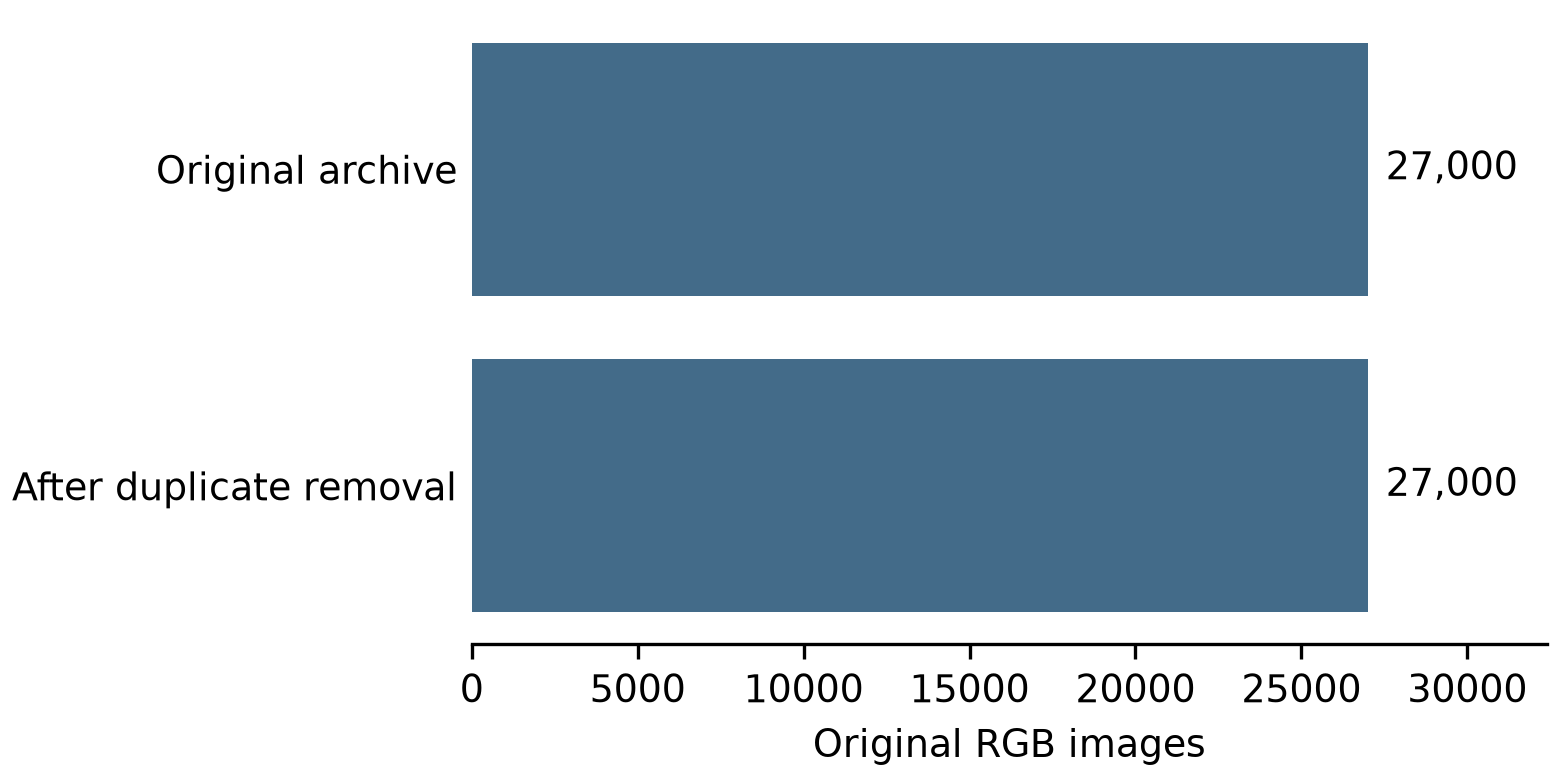

**Figure 1. Data cleaning audit.** Archive originals versus retained images after exact-pixel duplicate removal. No duplicates are fabricated for illustration.

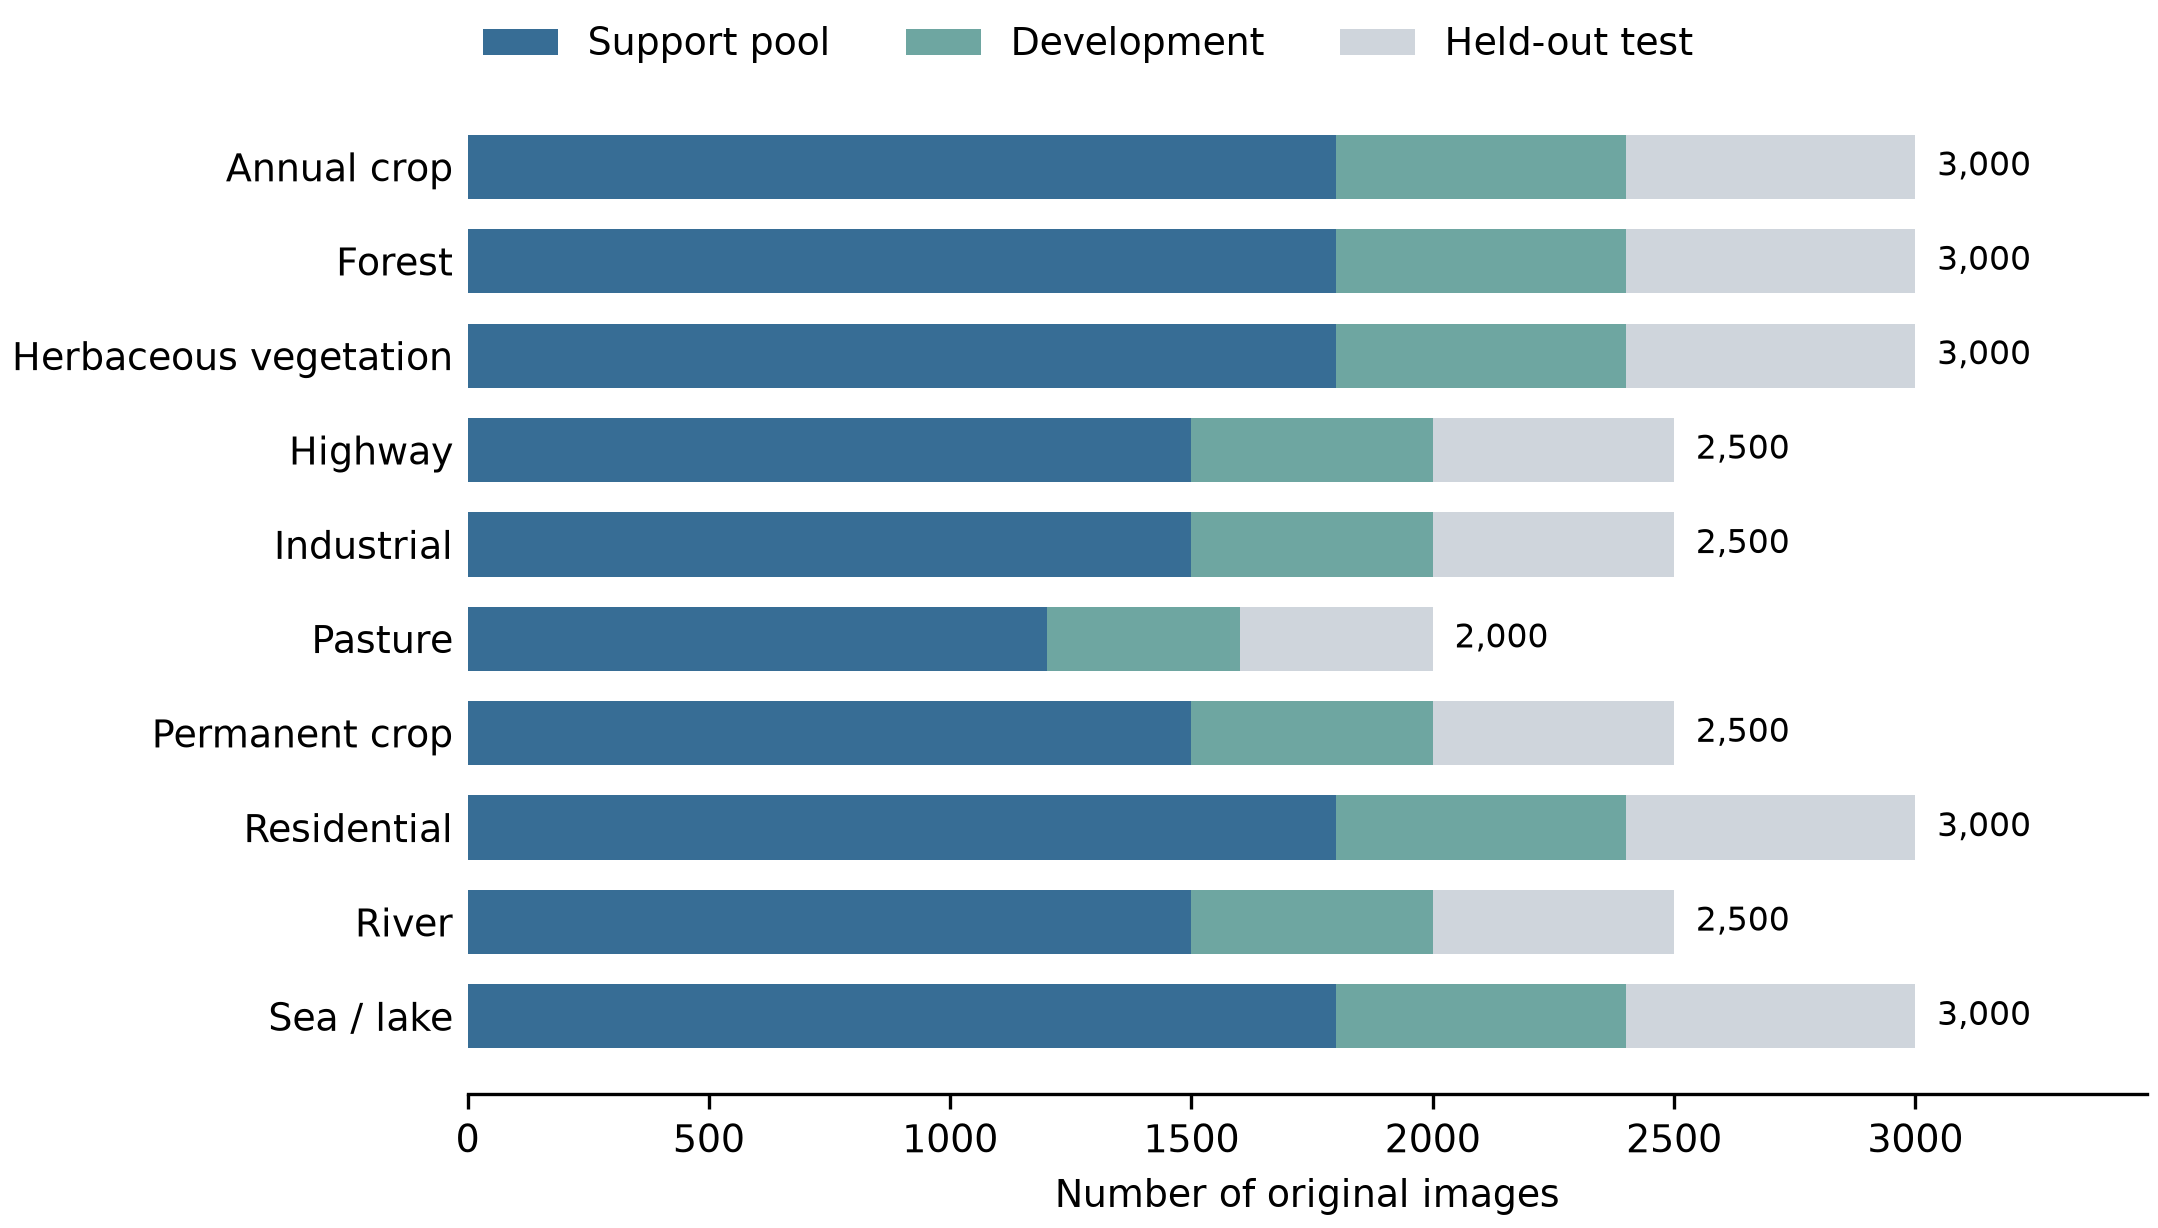

**Figure 2. Class balance and partitions.** Original image counts by class, divided into support, development and held-out test partitions.

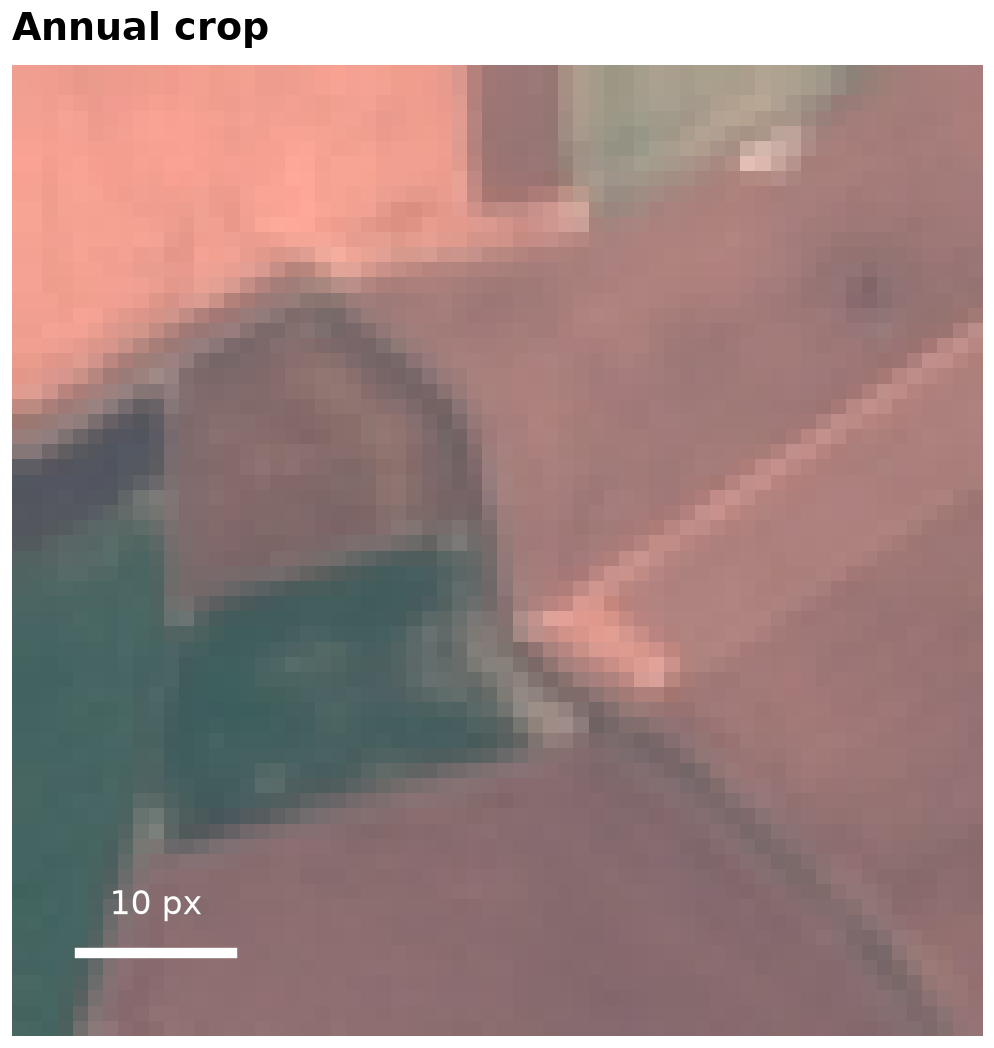

**Figure 3. One labeled EuroSAT image.** Native RGB tile from the annual-crop support pool. The scale marker is in pixels, not geographical distance.

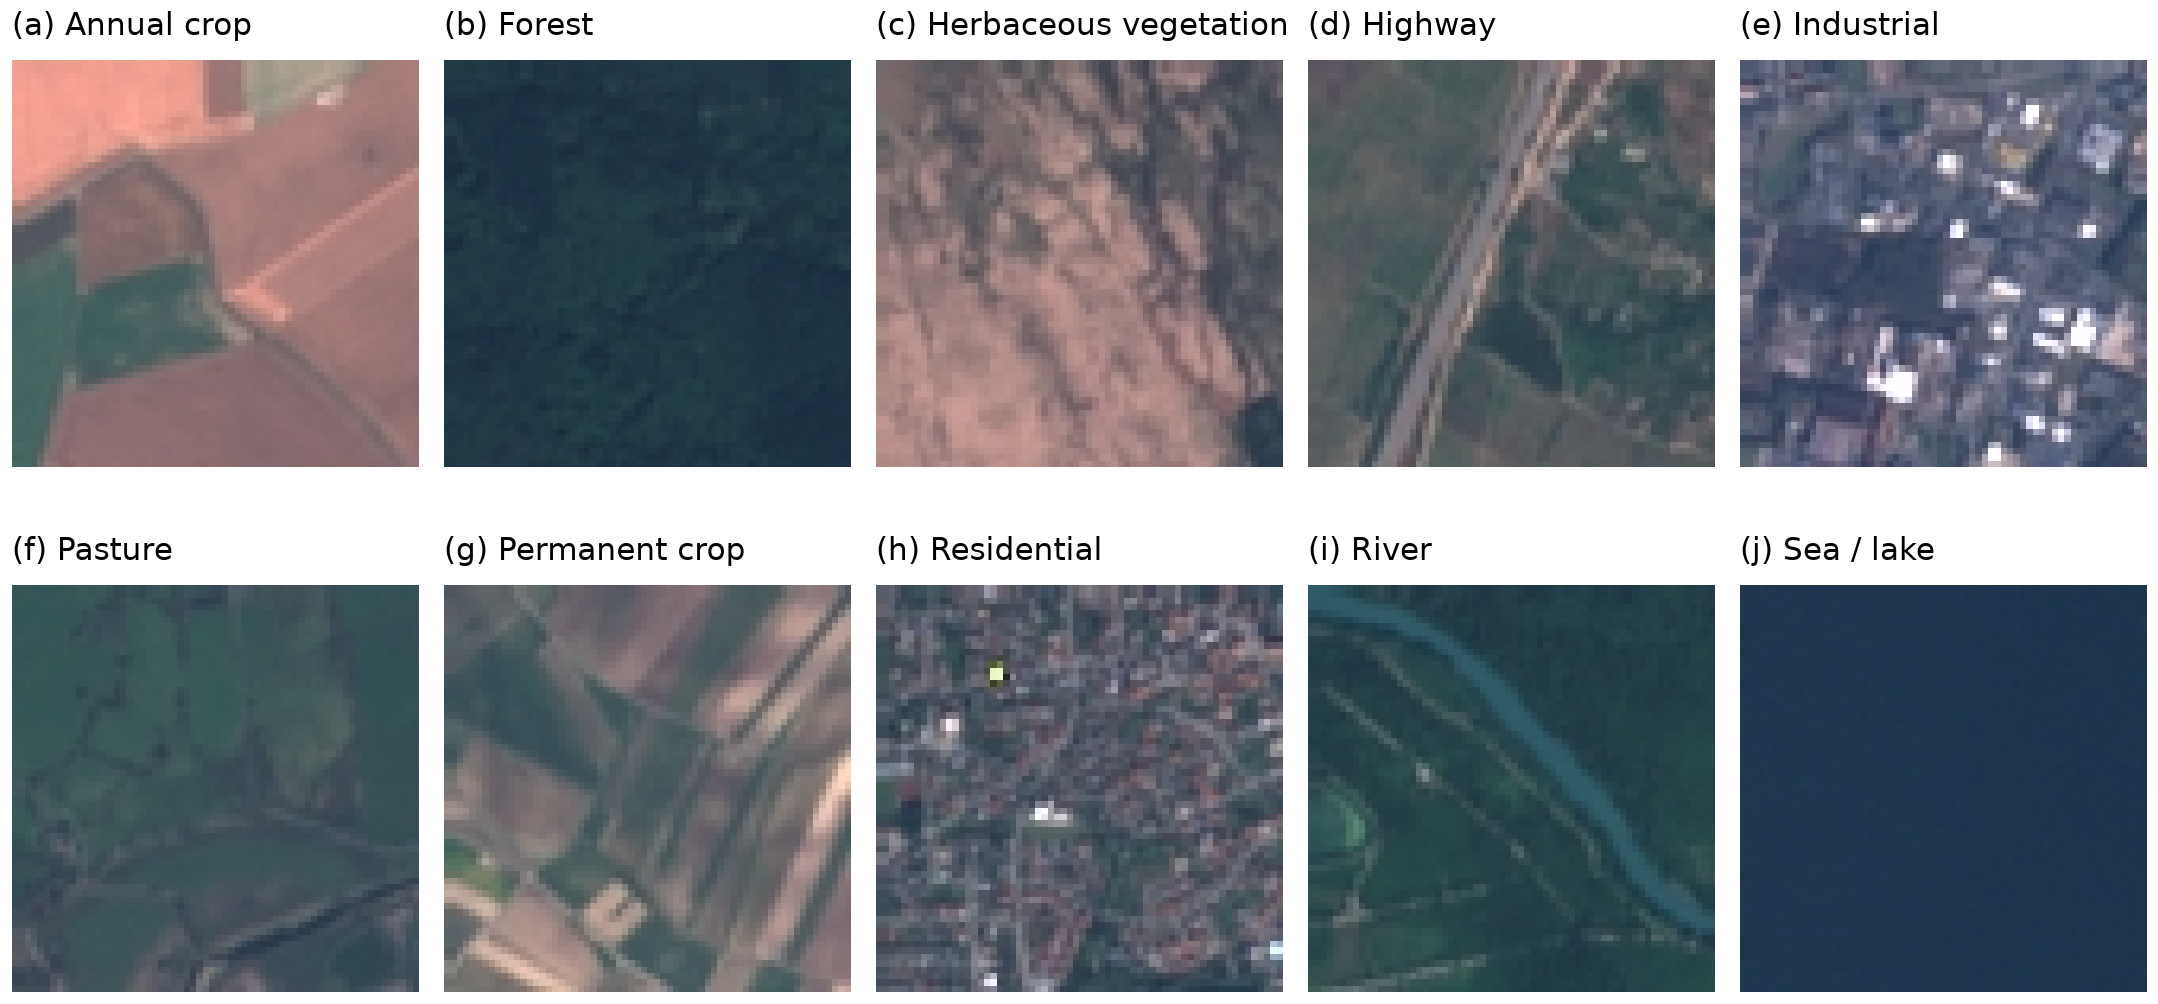

**Figure 4. Examples of all ten classes.** Unaugmented native RGB tiles sampled from the support pool with a fixed seed.

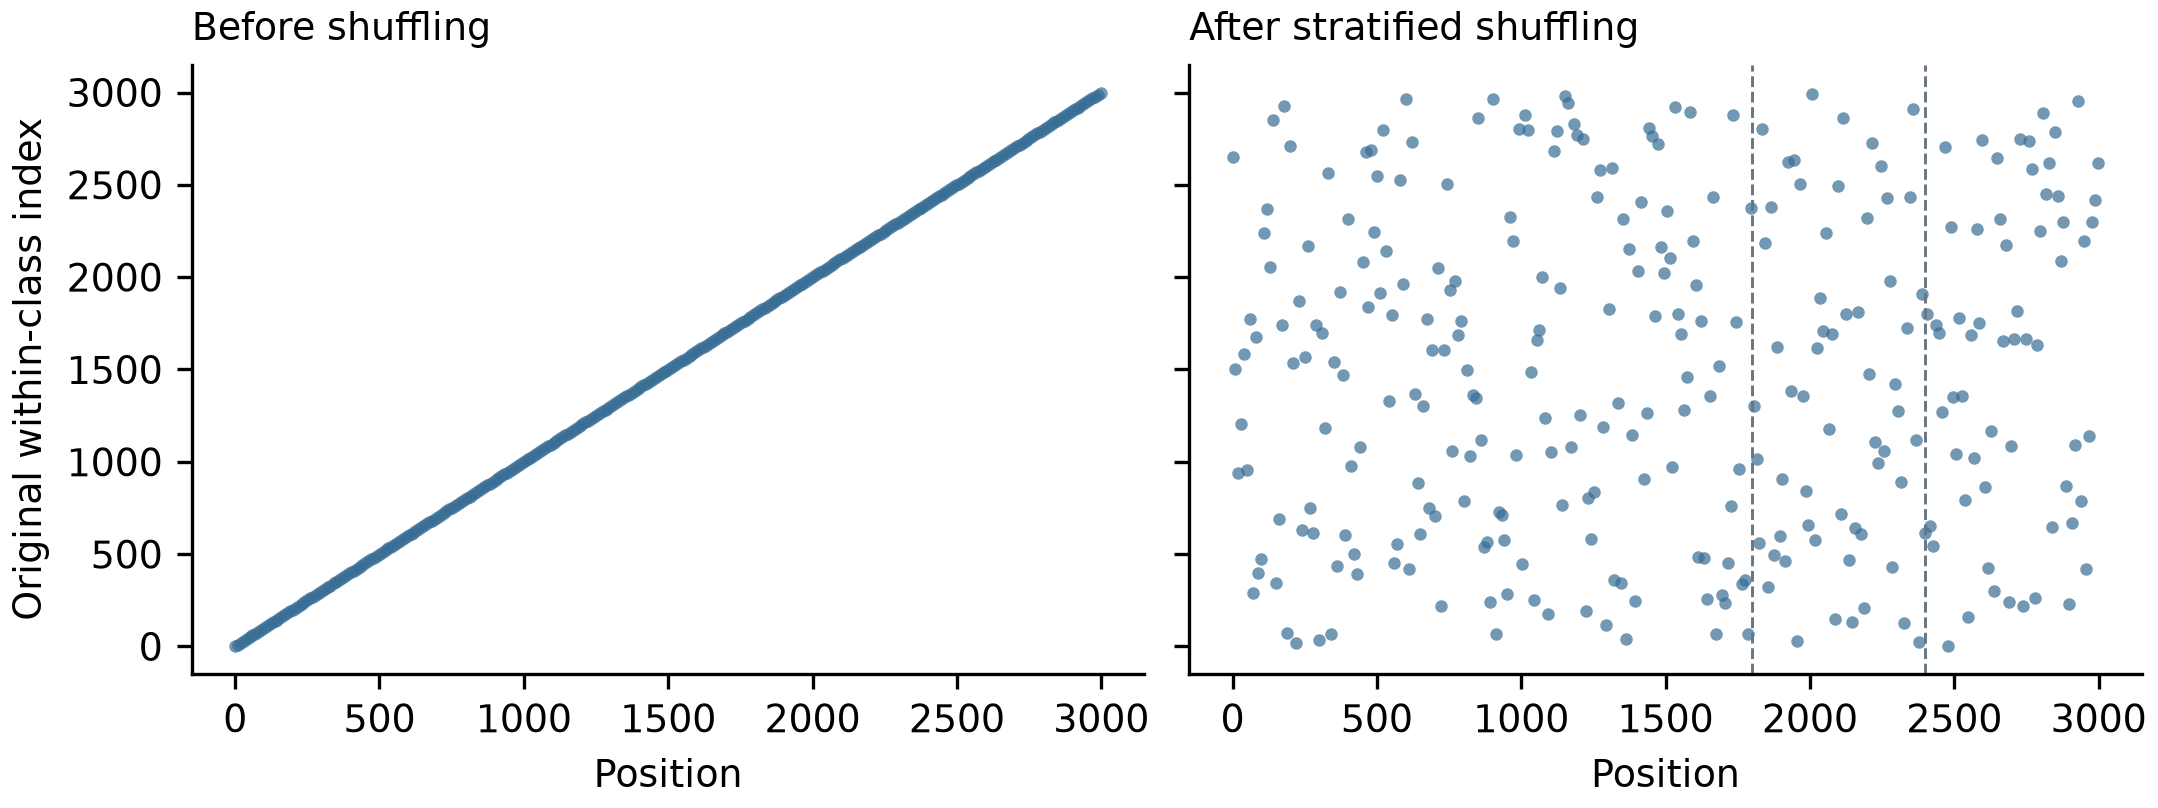

**Figure 5. Actual stratified shuffling.** The annual-crop class is shown before and after the permutation used for the split. Dashed boundaries mark support/development/test partitions; at most 300 evenly spaced positions are plotted. Every class uses the same procedure.

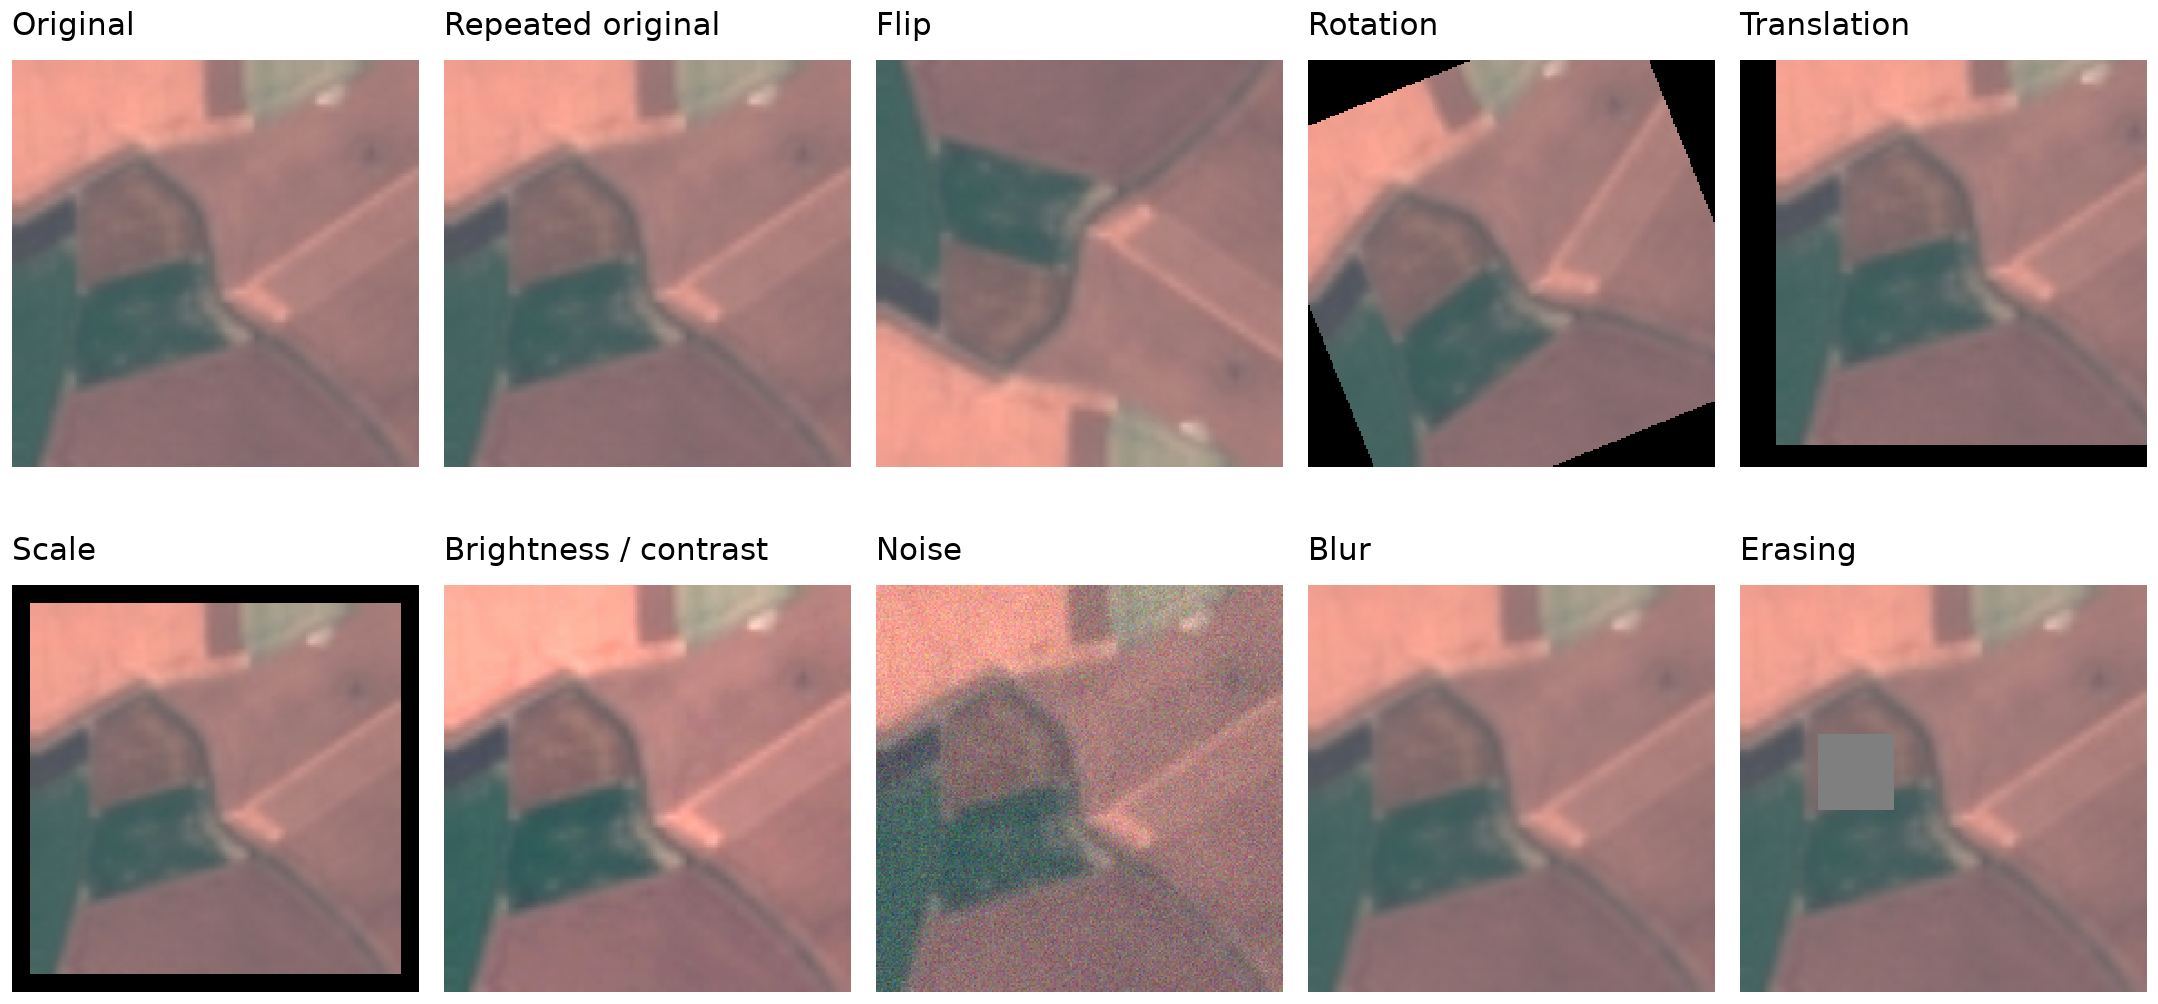

**Figure 6. Support-image augmentation policies.** One original support image, processed at 224 × 224, shown under the baseline, repeated-original control and individual augmentation methods. These views do not add labeled original shots.

Tables, 300-DPI PNGs, PDFs and image-source manifests: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/outputs/dataset/49e02e45e1ef9f12e484ee23d5372cd1bb422c9e496e151835b9348eb5ad3b79


In [16]:
import pandas as pd
from IPython.display import display, Markdown, Image as NotebookImage

dataset = explore(STORAGE, SCRATCH, config)
profile = dataset['profile']
display(pd.DataFrame({
    'Measure': ['Original images', 'Retained unique images', 'Classes', 'Native image sizes',
                'Color modes', 'Duplicates removed', 'Corrupt images', 'Cross-split image overlap',
                'Cross-split pixel overlap', 'Experiment scope'],
    'Value': [profile['original_images'], profile['images'], profile['classes'],
              str(profile['native_sizes']), str(profile['color_modes']), profile['duplicates_removed'],
              profile['corrupt_images'], profile['partition_overlap_images'],
              profile['partition_overlap_pixels'], MODE]
}))
display(pd.DataFrame(profile['class_counts']).set_index('class'))
captions = [
    ('cleaning_audit', '**Figure 1. Data cleaning audit.** Archive originals versus retained images after exact-pixel duplicate removal. No duplicates are fabricated for illustration.'),
    ('class_distribution', '**Figure 2. Class balance and partitions.** Original image counts by class, divided into support, development and held-out test partitions.'),
    ('example_tile', '**Figure 3. One labeled EuroSAT image.** Native RGB tile from the annual-crop support pool. The scale marker is in pixels, not geographical distance.'),
    ('class_examples', '**Figure 4. Examples of all ten classes.** Unaugmented native RGB tiles sampled from the support pool with a fixed seed.'),
    ('stratified_shuffle', '**Figure 5. Actual stratified shuffling.** The annual-crop class is shown before and after the permutation used for the split. Dashed boundaries mark support/development/test partitions; at most 300 evenly spaced positions are plotted. Every class uses the same procedure.'),
    ('augmentation_examples', '**Figure 6. Support-image augmentation policies.** One original support image, processed at 224 × 224, shown under the baseline, repeated-original control and individual augmentation methods. These views do not add labeled original shots.')
]
for name, caption in captions:
    display(NotebookImage(filename=dataset['figures'][name]['png'], width=360 if name == 'example_tile' else 820))
    display(Markdown(caption))
print('Tables, 300-DPI PNGs, PDFs and image-source manifests:', dataset['output'])


## 6. Four-person implementation map

Choose one primary owner and one reviewer for each part. Every model owner runs the **same complete policy grid** on their own backbone; augmentation ownership below concerns implementation and review, not omitting conditions. The proposal's comparisons require shared splits, original support images, query images, strengths, classifier rules and seeds.

Set `ASSIGNMENT` in section 1 to a backbone name to run only that model. The configuration cells in Parts A–D only prepare objects; they do not start experiments. Implement reusable behavior in the linked source files, rebuild this notebook, and use a pull request. Check completed work off here and in `TODO.md`.


### Part A — Shared data protocol and ResNet-18 baseline

**Suggested owner:** teammate 1 · **Reviewer:** teammate 4

Implementation: [`data.py`](src/eurosat/data.py), [`runtime.py`](src/eurosat/runtime.py), [`models.py`](src/eurosat/models.py), [`exploration.py`](src/eurosat/exploration.py).

- [x] Verified RGB archive, decoded-pixel duplicate checks and class labels.
- [x] Stratified 60/20/20 partitions and nested, paired 1/5/10-shot support sets.
- [x] Frozen ResNet-18 adapter and full-dataset EDA figures.
- [ ] Agree on and freeze the shared dataset/seed/protocol manifest.
- [ ] Complete the full ResNet grid and export `results.json`.
- [ ] Have a second teammate verify data isolation and reproducibility.
- [ ] Resolve geographic-grouping feasibility or document the limitation.


In [17]:
# Part A implementation TODO: make shared-protocol changes in data.py/config.py,
# and the ResNet representation adapter in models.py. Do not change test partitions here.
# Set ASSIGNMENT = 'resnet18' in section 1 for this teammate's execution.
part_a_config = replace(config, models=['resnet18'])
print('Part A:', part_a_config.models)


Part A: ['resnet18']


### Part B — ConvNeXt-Tiny and geometric augmentation validation

**Suggested owner:** teammate 2 · **Reviewer:** teammate 1

Implementation: [`models.py`](src/eurosat/models.py), [`augment.py`](src/eurosat/augment.py), [`features.py`](src/eurosat/features.py).

- [x] ImageNet-1K ConvNeXt-Tiny, pooled features and final checkpoint normalization.
- [x] Flip, rotation, translation and scaling policies with deterministic image/view seeds.
- [ ] Review geometric strengths using development data; freeze choices before test reporting.
- [ ] Complete the full ConvNeXt grid, including every non-geometric control/condition.
- [ ] Report paired gains and compare modern-CNN versus ResNet representations.
- [ ] Review the shared split and augmentation-view manifests with Part A.


In [18]:
# Part B implementation TODO: geometric transforms belong in augment.py;
# ConvNeXt feature extraction belongs in models.py. Reuse the common classifier.
# Set ASSIGNMENT = 'convnext_tiny' in section 1 to execute this model only.
part_b_config = replace(config, models=['convnext_tiny'])
print('Part B:', part_b_config.models)


Part B: ['convnext_tiny']


### Part C — ViT-B/16 and color/pixel augmentation validation

**Suggested owner:** teammate 3 · **Reviewer:** teammate 2

Implementation: [`models.py`](src/eurosat/models.py), [`augment.py`](src/eurosat/augment.py), [`features.py`](src/eurosat/features.py).

- [x] ImageNet-1K ViT-B/16 final normalized class-token representation.
- [x] Brightness/contrast, noise, blur and erasing conditions, with support-only augmentation.
- [ ] Confirm preprocessing, feature dimensions and frozen evaluation behavior.
- [ ] Review policy strengths on development data; keep views identical across models.
- [ ] Complete the full ViT grid and export paired comparisons with both CNNs.
- [ ] Prespecify selected 1-shot nine-view comparisons; cutout remains optional.


In [19]:
# Part C implementation TODO: color/noise/blur/erasing policies belong in augment.py;
# ViT representation extraction belongs in models.py. Keep original shot budgets unchanged.
# Set ASSIGNMENT = 'vit_b_16' in section 1 to execute this model only.
part_c_config = replace(config, models=['vit_b_16'])
print('Part C:', part_c_config.models)


Part C: ['vit_b_16']


### Part D — DINOv2, statistical summaries and report integration

**Suggested owner:** teammate 4 · **Reviewer:** teammate 3

Implementation: [`models.py`](src/eurosat/models.py), [`evaluation.py`](src/eurosat/evaluation.py), [`reporting.py`](src/eurosat/reporting.py).

- [x] Official pinned DINOv2 ViT-S/14 checkpoint and frozen class-token features.
- [x] Common logistic regression, Macro-F1, recall, confusion matrices and paired gains.
- [x] Implement the complete DINOv2 main grid and record checkpoint/software provenance.
- [x] Implement development-only strength selection, four-/nine-view label-budget comparisons and resumable suite execution.
- [x] Export Macro-F1, class augmentation effects, negative findings and stage time/memory measurements.
- [ ] Finish full-data execution on the intended GPU and review results.
- [x] Validate complete paired exports and generate development-selected policy tables.
- [ ] Merge all four full-grid assignments (depends on teammates A–C).
- [x] Implement model-by-shot, paired augmentation-gain, class-recall and confusion-matrix figures.
- [ ] Produce full-grid figures after the four model assignments complete.
- [ ] Report development-label use, timing conditions, negative findings and pretraining confounds.
- [ ] Coordinate final methods, limitations and citations; do not attribute DINOv2/ViT differences to self-supervision alone.


In [20]:
# Part D implementation TODO: keep metric/classifier rules in evaluation.py;
# combine completed exports through reporting.py rather than hand-editing CSVs.
# Set ASSIGNMENT = 'dinov2_vits14' in section 1 to execute this model only.
part_d_config = replace(config, models=['dinov2_vits14'])
part_d_config.validate()
print('Part D:', part_d_config.models, '| pinned checkpoint:', MODEL_IDS['dinov2_vits14'])


Part D: ['dinov2_vits14'] | pinned checkpoint: facebookresearch/dinov2:7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2_vits14


## 7. Run or resume the selected experiment

Only support images receive random augmentation. Development and test preprocessing are deterministic. Feature extraction is cached in chunks, classifier parameters are stored as numeric checkpoints, and completed trials are skipped. This cell does not repeat dataset cleaning or GPU work that has already completed for the same configuration.


In [21]:
if EXPERIMENT == 'part-d':
    suite = run_part_d(STORAGE, SCRATCH, target=TARGET, mode=MODE, config=config,
                       select_strengths=SELECT_STRENGTHS, include_cutout=INCLUDE_CUTOUT,
                       selected_methods=NINE_VIEW_METHODS, include_resnet=INCLUDE_RESNET_BASELINE)
    results = suite['combined'] or suite['primary']
else:
    suite = None
    results = run(config, STORAGE, SCRATCH, target=TARGET)


Data: 400 unique images, splits {'support': 240, 'dev': 80, 'test': 80}; 0 exact-pixel duplicates removed


Data: 400 unique images, splits {'support': 240, 'dev': 80, 'test': 80}; 0 exact-pixel duplicates removed


Development strength selection reused: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/cache/development/1c295ff80e5c5b37ae53c90794c390e9e886714a6046650119b18a5706824736/selection.json


Compute: mps [mps] — device check passed


Data: 400 unique images, splits {'support': 240, 'dev': 80, 'test': 80}; 0 exact-pixel duplicates removed


Completed results reused: dinov2_vits14


... (10 outputs left out)

Completed results reused: dinov2_vits14


Finished. Results: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/outputs/81a2be17021978b5a43d292152b4801a074a87fe37a1369b4b4a5b44c583efff


Result figures and tables: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/outputs/81a2be17021978b5a43d292152b4801a074a87fe37a1369b4b4a5b44c583efff/report


Part D suite complete: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/outputs/part-d/401470fd576076ccd1bd7571958978a50b1818ccfb20ec00c8d6ef62281de667


## 8. Results and reporting

Accuracy, precision, recall and F1 are fractions; paired improvements are percentage points relative to each trial's unaugmented baseline. Preferred policies are selected from development performance, while all prespecified comparisons remain available in the exported results. Smoke scores below validate execution only.


In [22]:
table = pd.DataFrame(results['summary'])
columns = ['model', 'shots', 'policy', 'accuracy', 'macro_precision', 'macro_recall',
           'macro_f1', 'balanced_accuracy', 'weighted_f1', 'paired_gain_percentage_points']
display(table[columns].sort_values(['model', 'shots', 'policy']).reset_index(drop=True).round(3))
intervals = ['model', 'shots', 'policy', 'accuracy_ci95_low', 'accuracy_ci95_high',
             'macro_f1_ci95_low', 'macro_f1_ci95_high',
             'paired_gain_percentage_points_ci95_low', 'paired_gain_percentage_points_ci95_high']
display(table[intervals].round(3))
print('95% intervals bootstrap support trials conditional on fixed queries; unavailable below 5 trials.')
print('Results, classifier records and development-selected policies:', results['output'])


,model,shots,policy,accuracy,macro_precision,macro_recall,macro_f1,balanced_accuracy,weighted_f1,paired_gain_percentage_points
0,dinov2_vits14,1,blur,0.525,0.528,0.525,0.496,0.525,0.496,0.625
1,dinov2_vits14,1,brightness_contrast,0.544,0.547,0.544,0.515,0.544,0.515,2.500
2,dinov2_vits14,1,erasing,0.525,0.534,0.525,0.497,0.525,0.497,0.625
3,dinov2_vits14,1,flip,0.556,0.580,0.556,0.528,0.556,0.528,3.750
4,dinov2_vits14,1,noise,0.550,0.556,0.550,0.524,0.550,0.524,3.125
5,dinov2_vits14,1,none,0.519,0.530,0.519,0.486,0.519,0.486,0.000
6,dinov2_vits14,1,repeat,0.512,0.513,0.512,0.481,0.512,0.481,-0.625
7,dinov2_vits14,1,rotation,0.550,0.565,0.550,0.518,0.550,0.518,3.125
8,dinov2_vits14,1,scale,0.594,0.638,0.594,0.570,0.594,0.570,7.500
9,dinov2_vits14,1,translation,0.519,0.576,0.519,0.486,0.519,0.486,-0.000


,model,shots,policy,accuracy_ci95_low,accuracy_ci95_high,macro_f1_ci95_low,macro_f1_ci95_high,paired_gain_percentage_points_ci95_low,paired_gain_percentage_points_ci95_high
0,dinov2_vits14,1,blur,None,None,None,None,None,None
1,dinov2_vits14,5,blur,None,None,None,None,None,None
2,dinov2_vits14,10,blur,None,None,None,None,None,None
3,dinov2_vits14,1,brightness_contrast,None,None,None,None,None,None
4,dinov2_vits14,5,brightness_contrast,None,None,None,None,None,None
5,dinov2_vits14,10,brightness_contrast,None,None,None,None,None,None
6,dinov2_vits14,1,erasing,None,None,None,None,None,None
7,dinov2_vits14,5,erasing,None,None,None,None,None,None
8,dinov2_vits14,10,erasing,None,None,None,None,None,None
9,dinov2_vits14,1,flip,None,None,None,None,None,None


95% intervals bootstrap support trials conditional on fixed queries; unavailable below 5 trials.
Results, classifier records and development-selected policies: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/outputs/part-d/401470fd576076ccd1bd7571958978a50b1818ccfb20ec00c8d6ef62281de667/model-baseline


### Part D: visualize metrics and proposal baselines

The Part D suite uses 1-shot development labels to lock strengths, runs the primary grid, selects nine-view methods on primary development accuracy, and then evaluates the follow-up. These figures use the selected run above. The ResNet-18 baseline uses identical partitions, supports, strengths and classifier rules. No-augmentation and repeated-original controls are retained. The baseline plots use the unaugmented condition; augmentation gains pair each trial with the same original support/query images. Error bars show trial standard deviation, not a confidence interval. Policies are selected from development accuracy only. Smoke figures check execution and are not paper results.


**Model by shot**

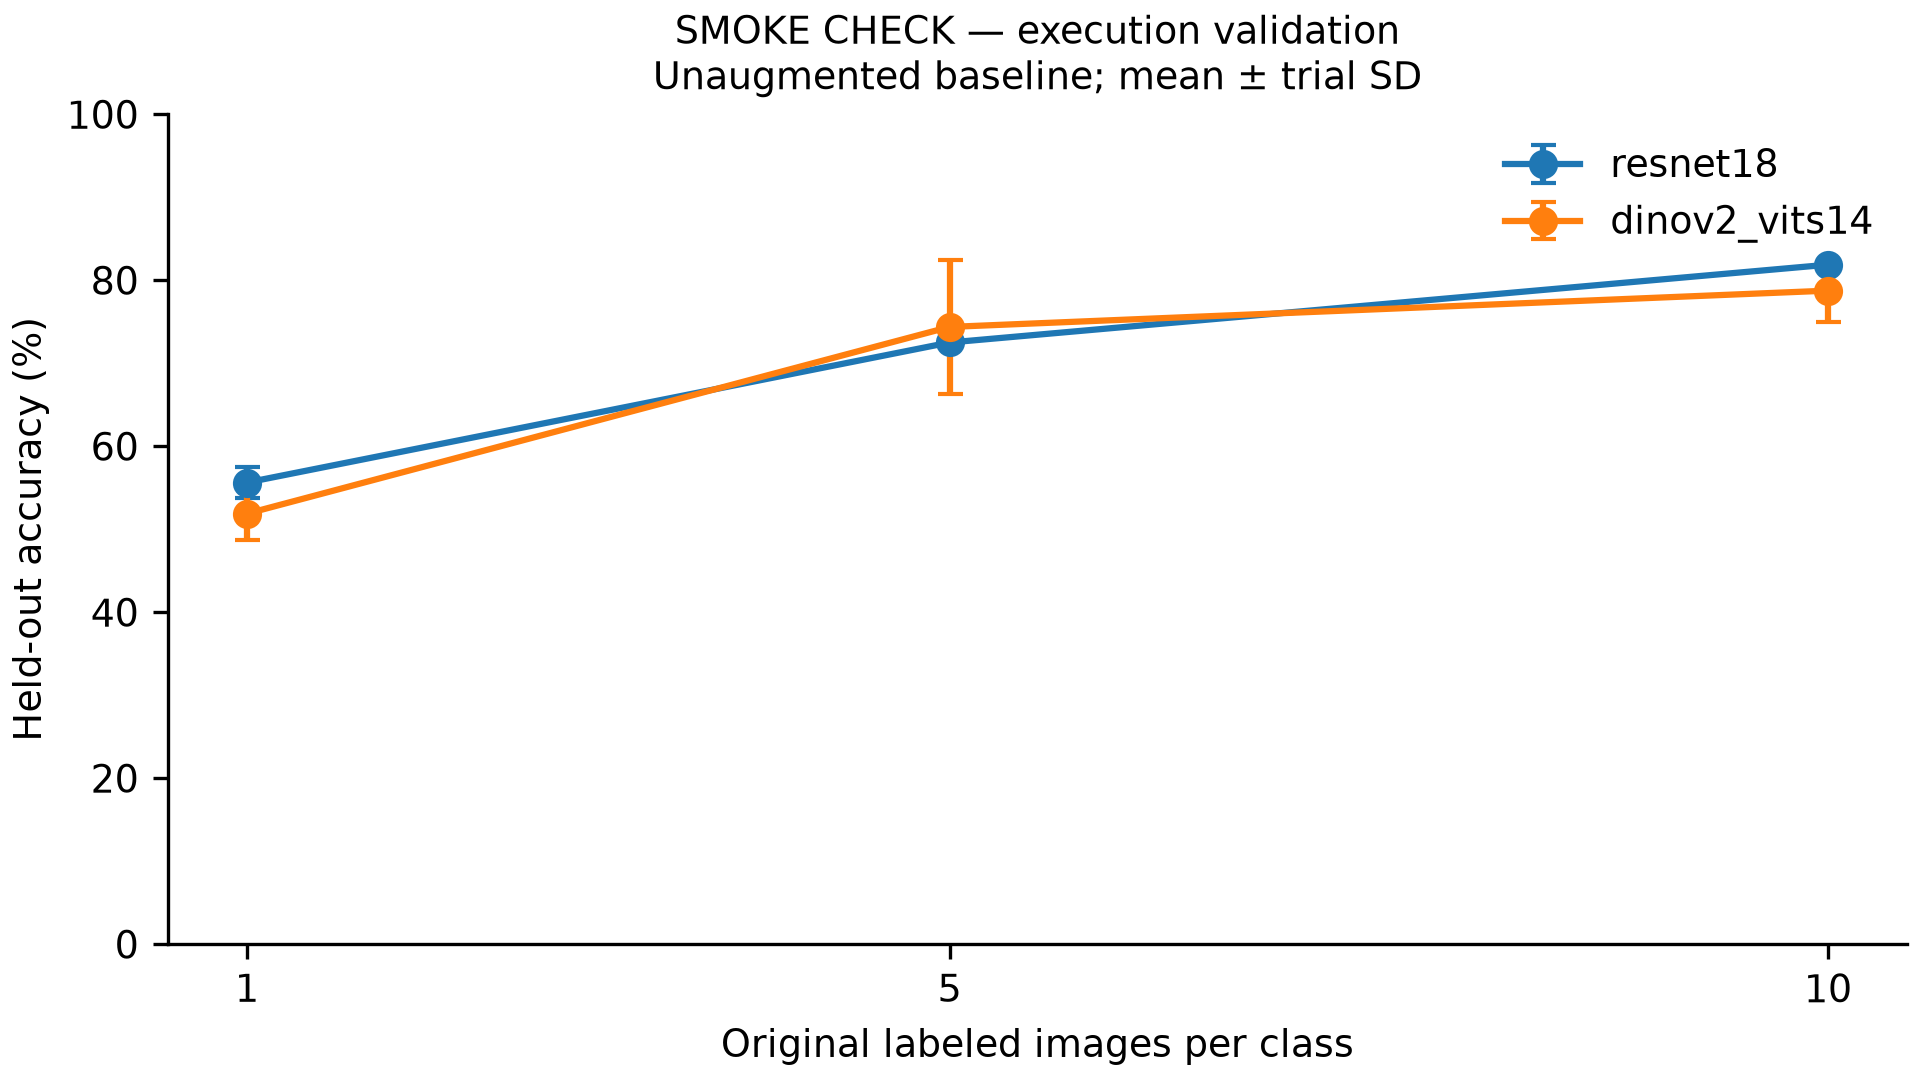

**Augmentation gains**

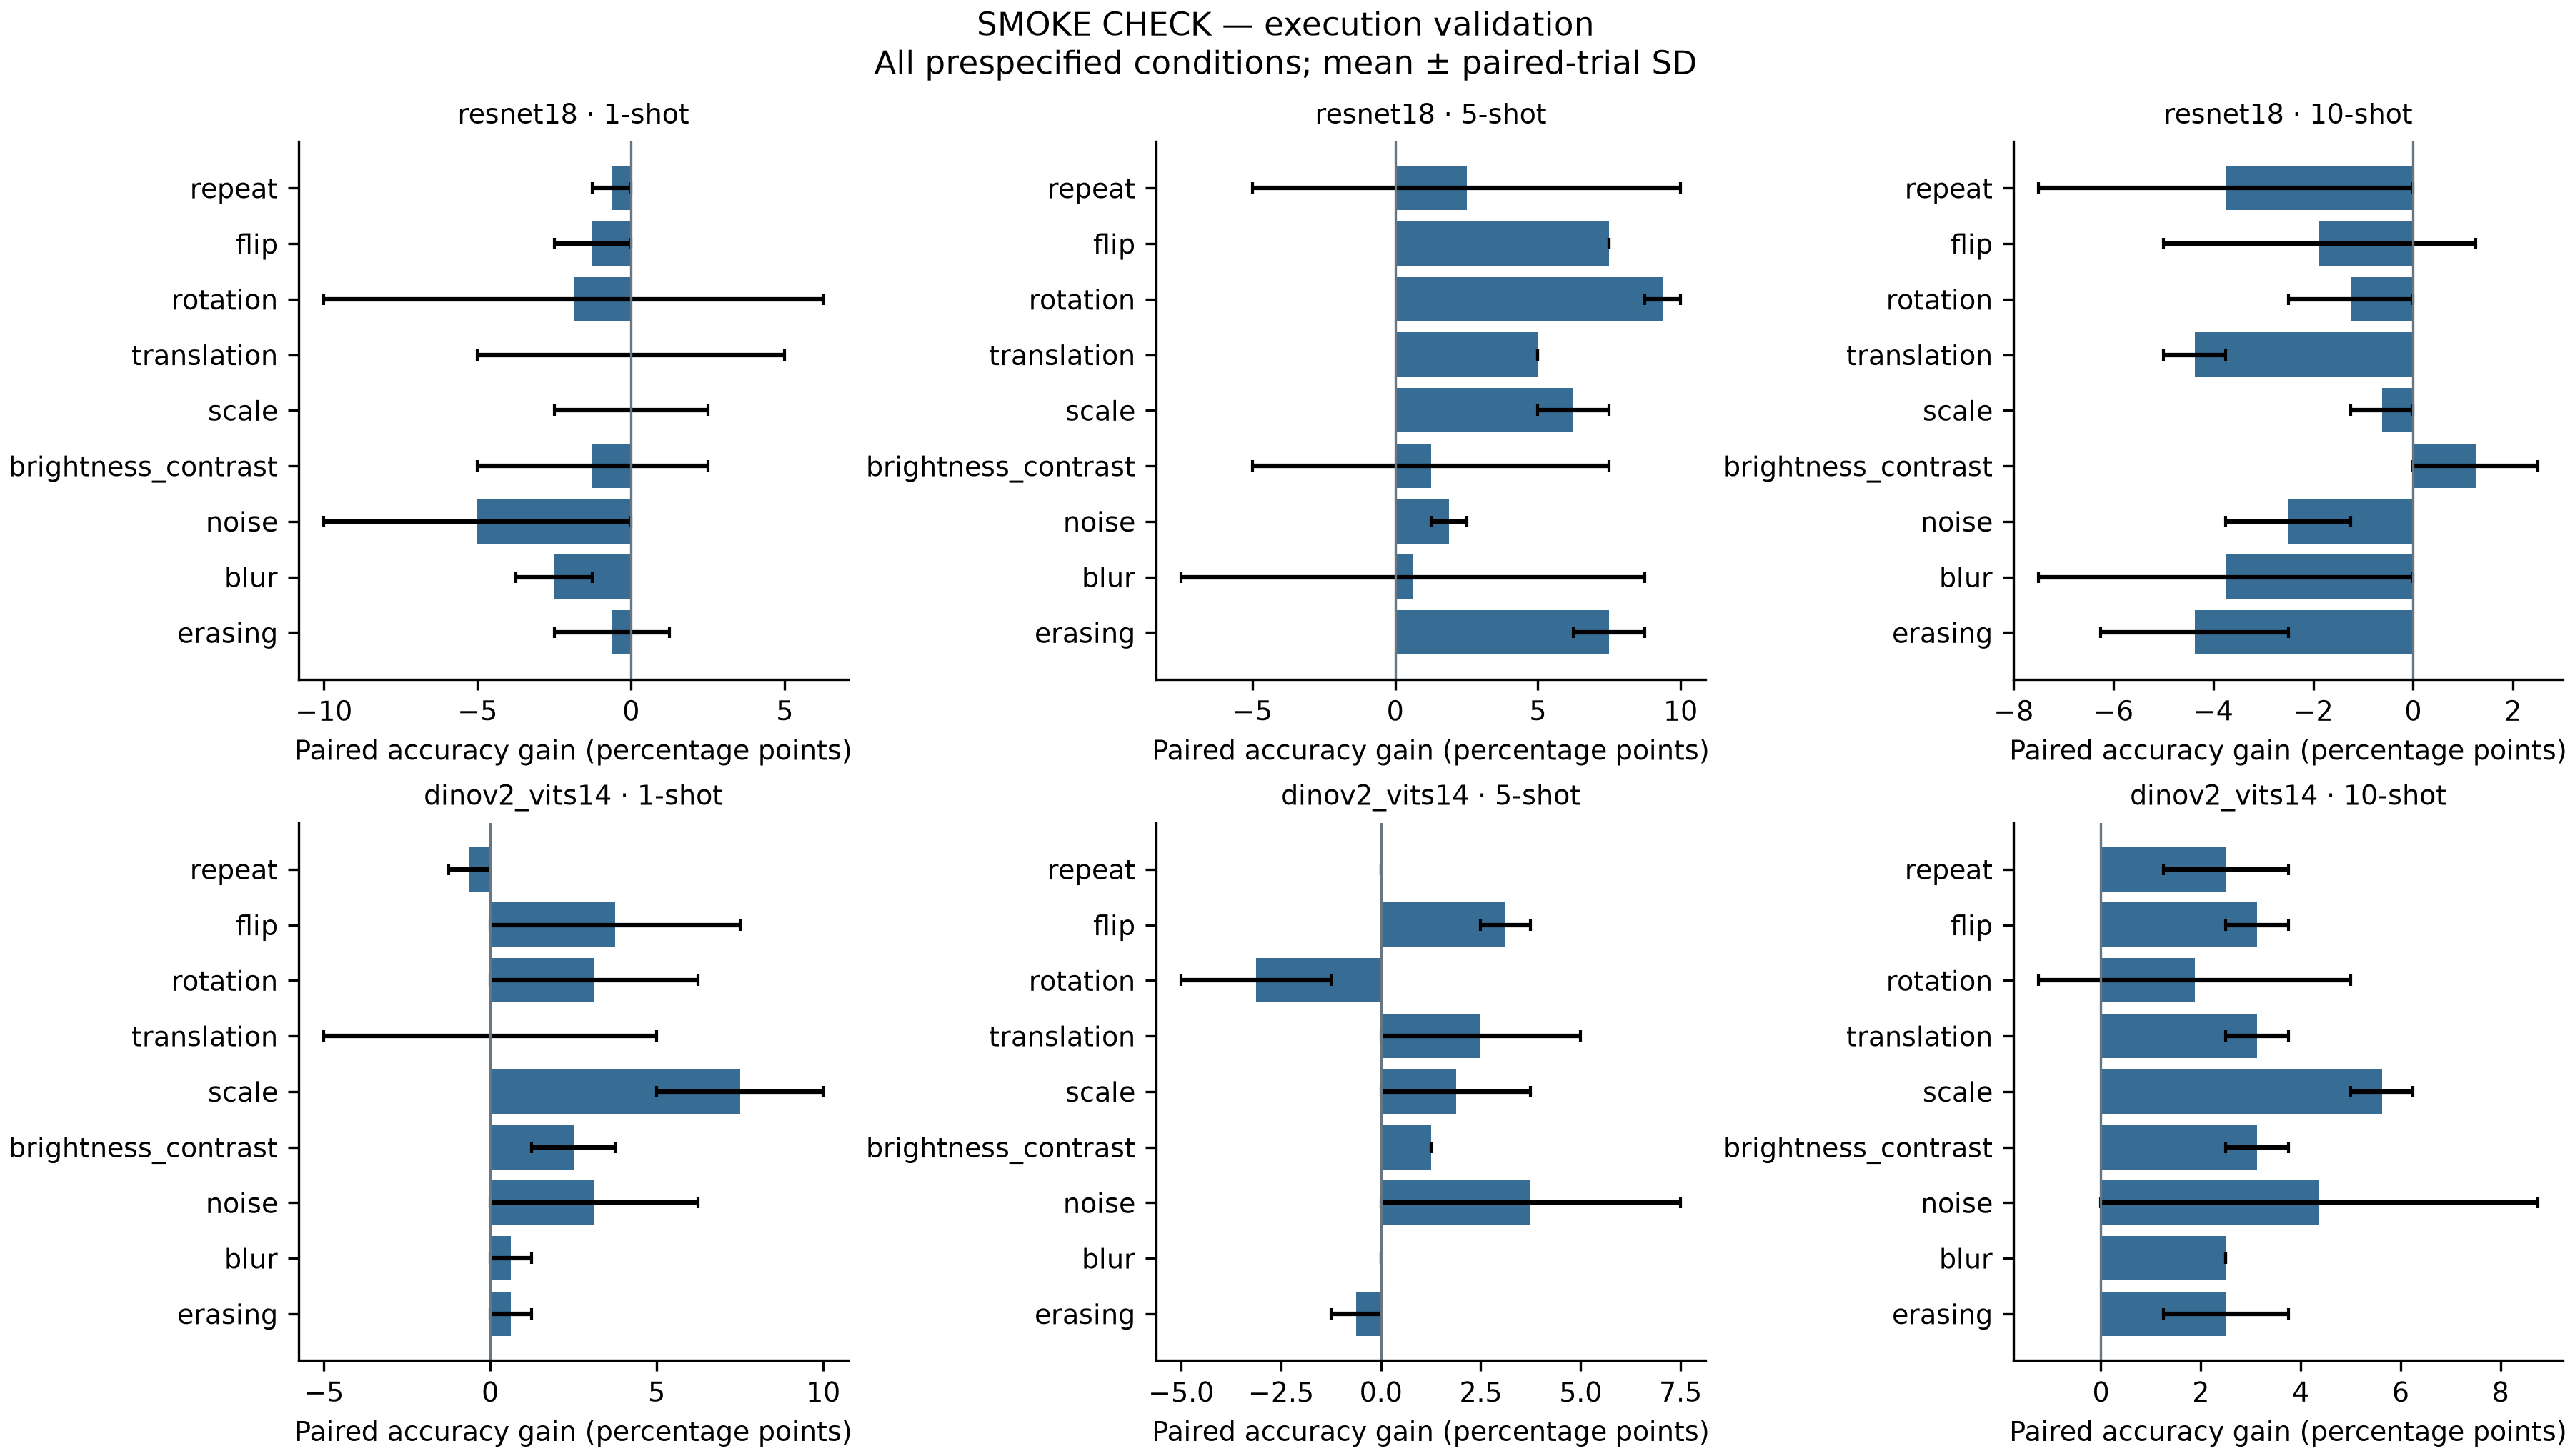

**Class recall**

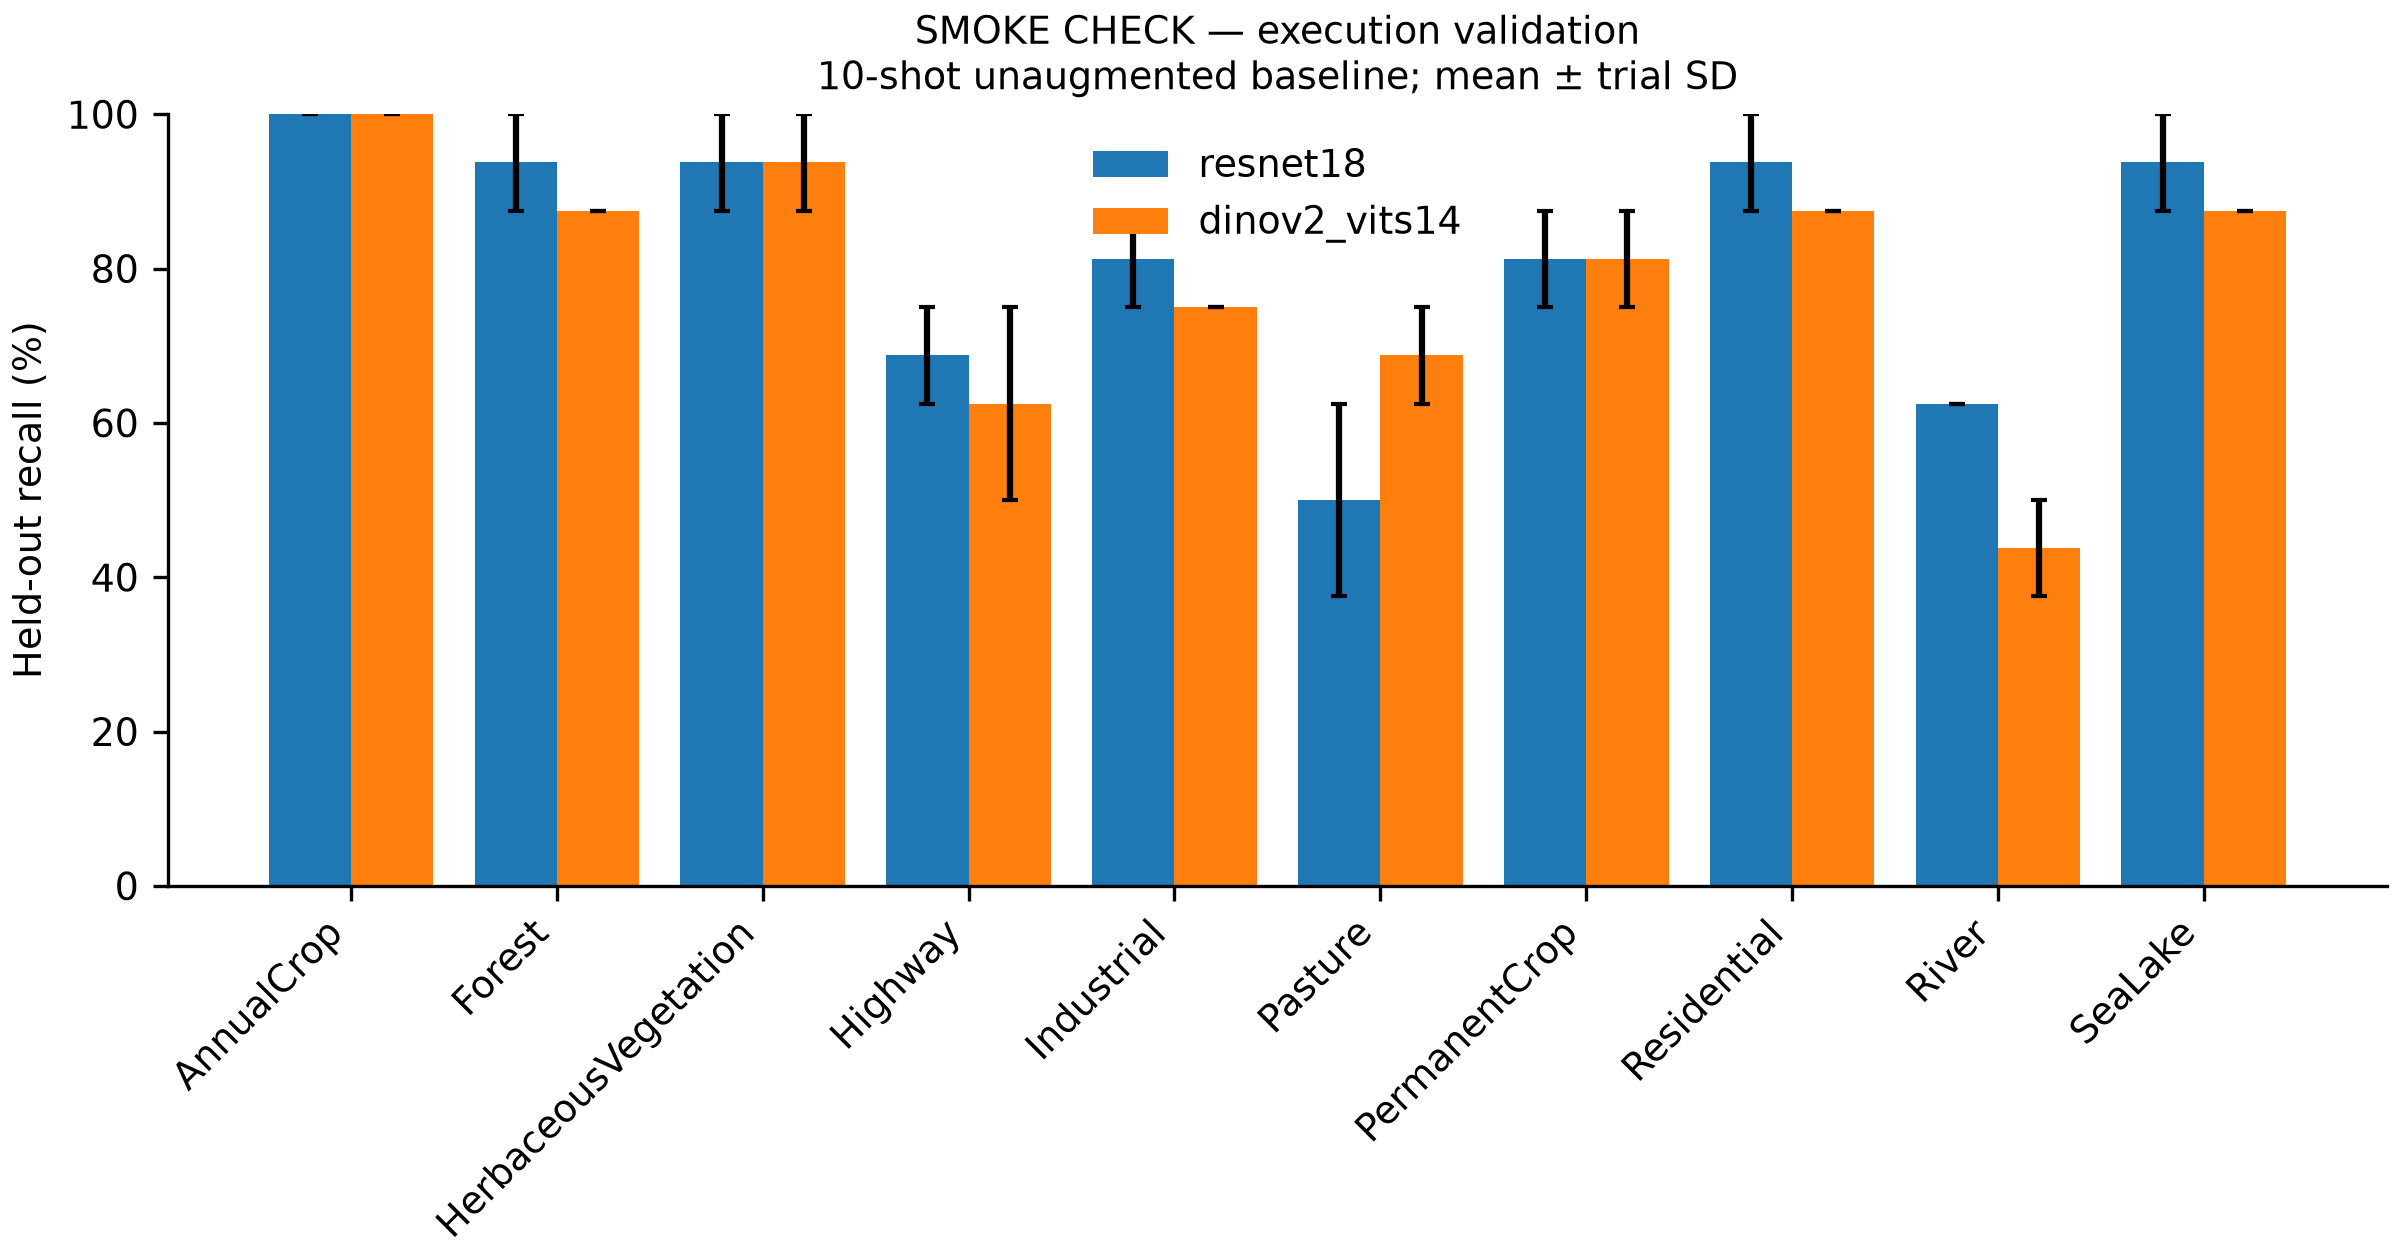

**Confusion matrix**

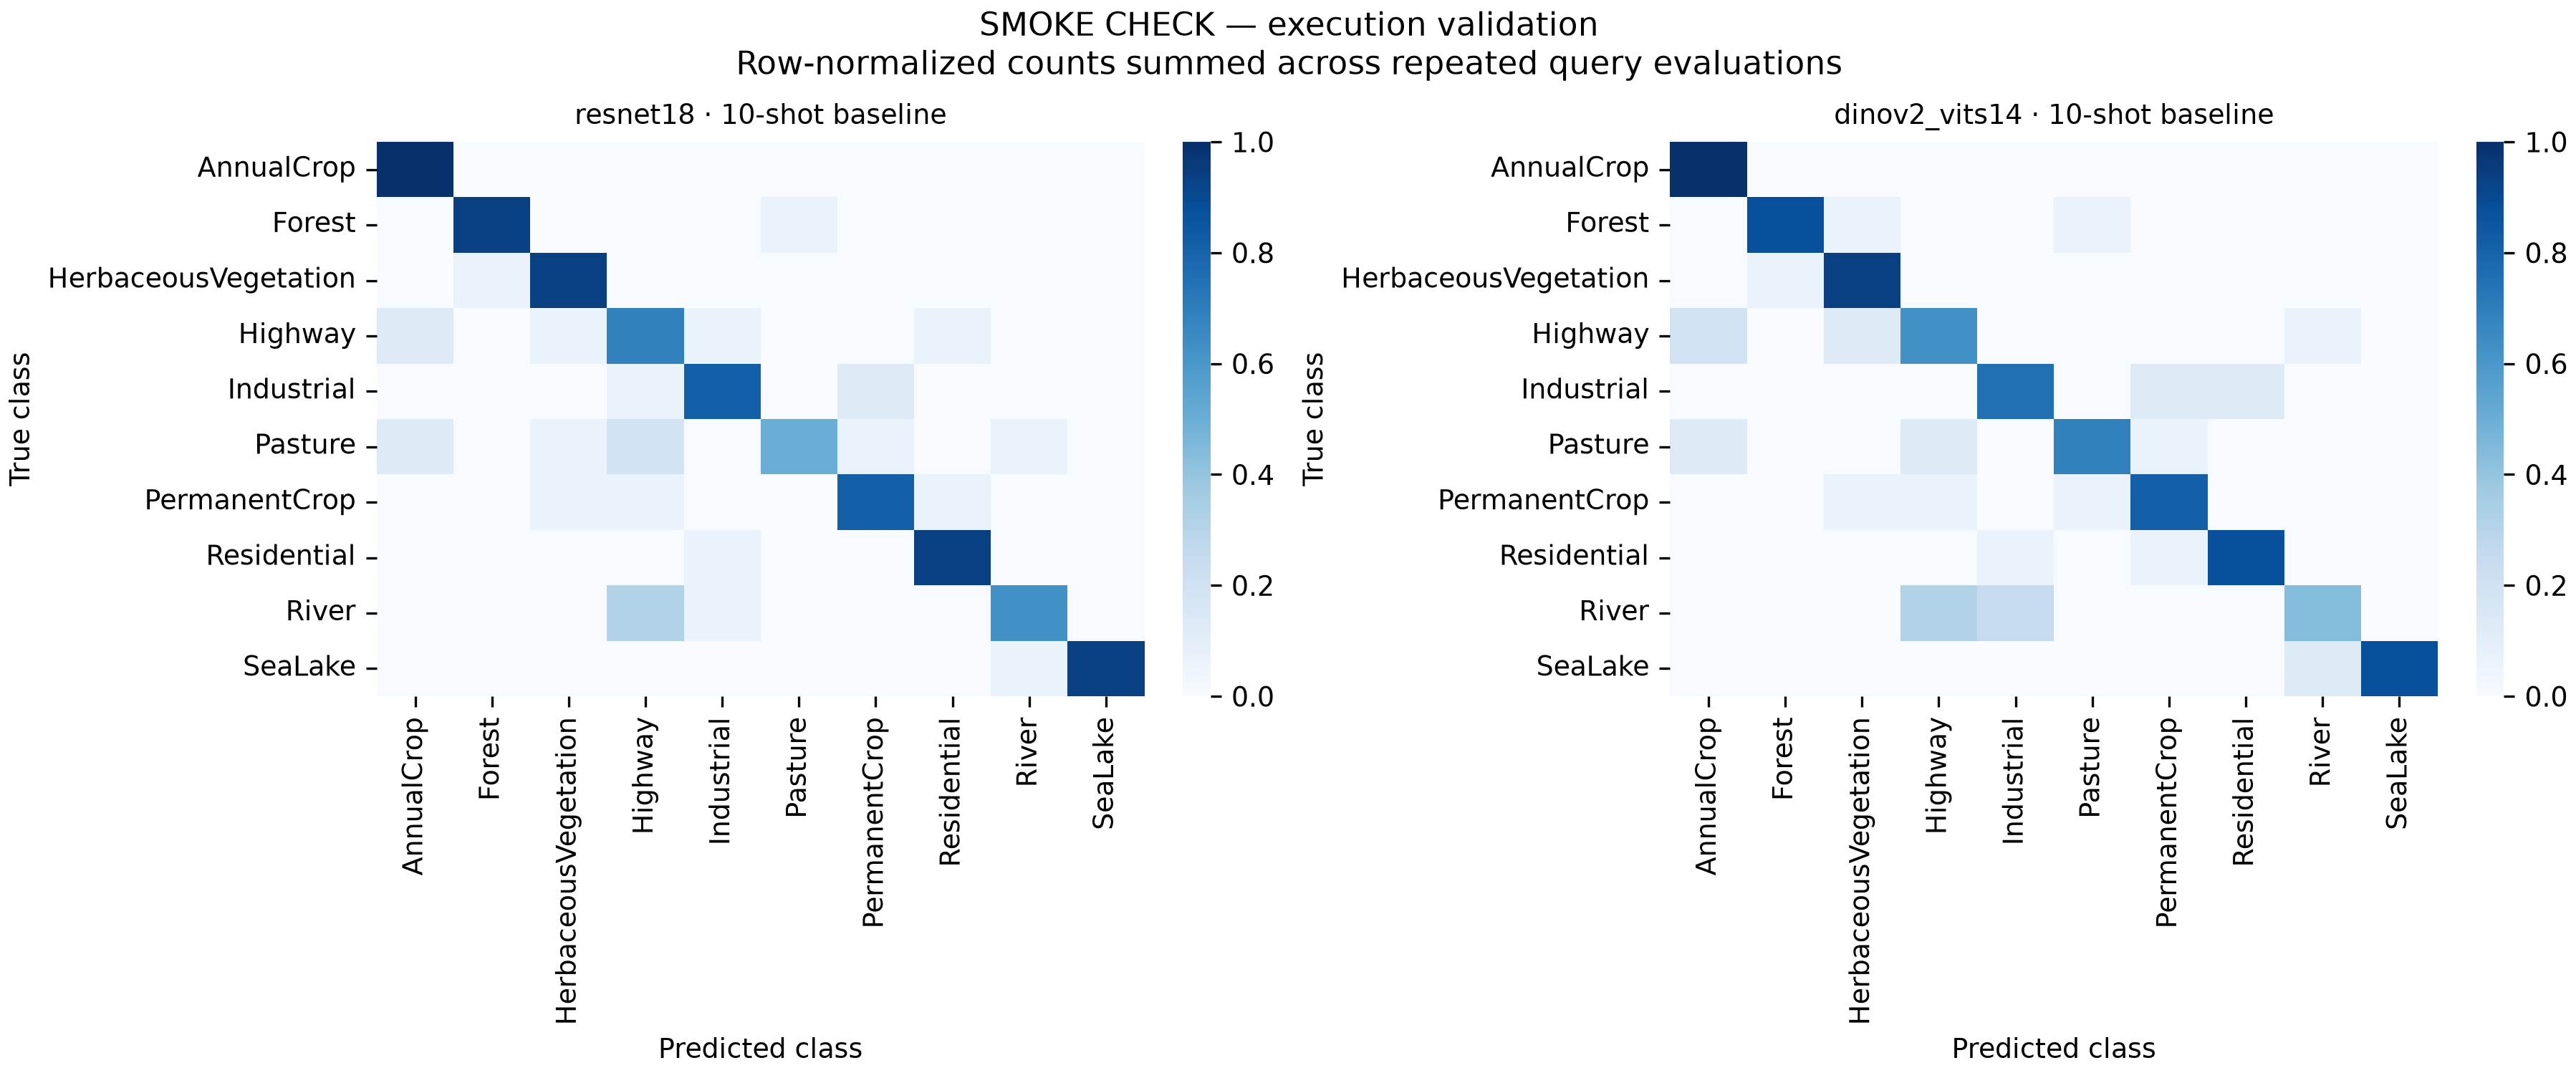

**Macro f1 by shot**

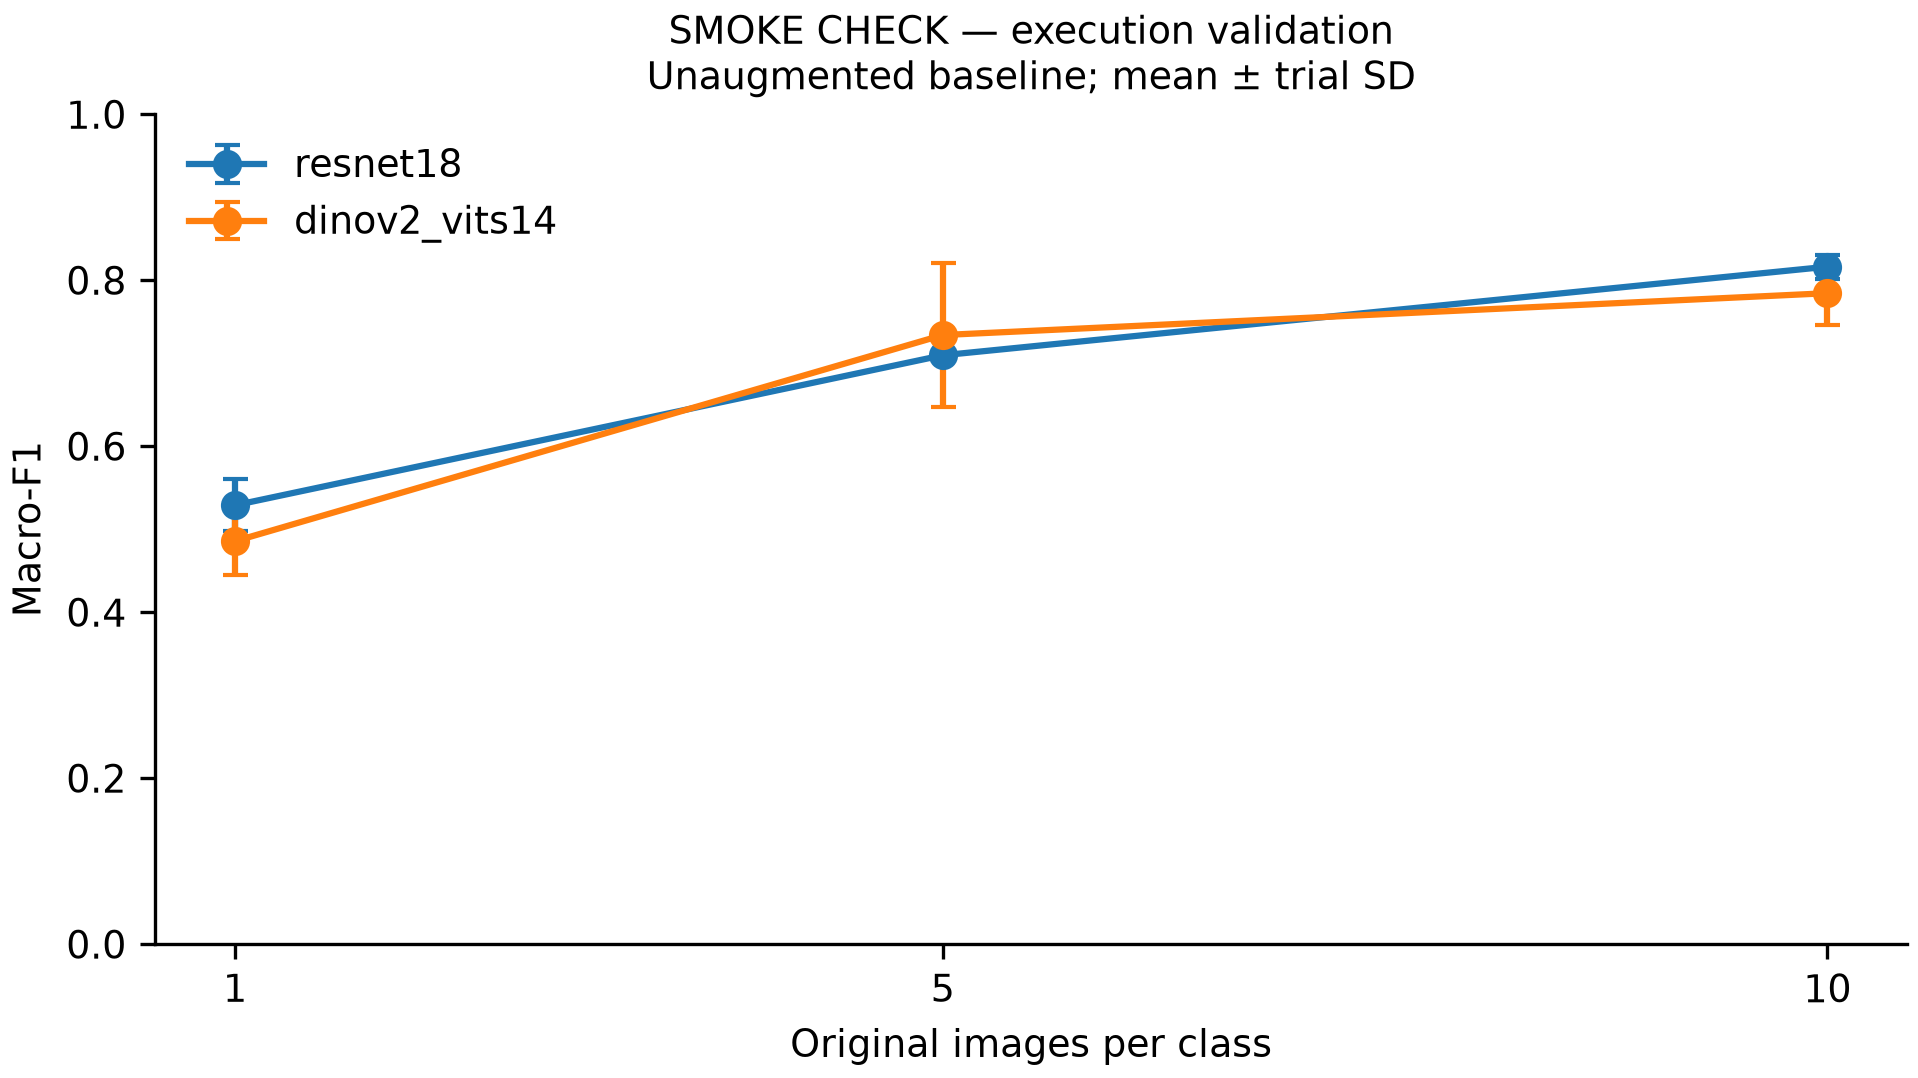

**Class augmentation deltas**

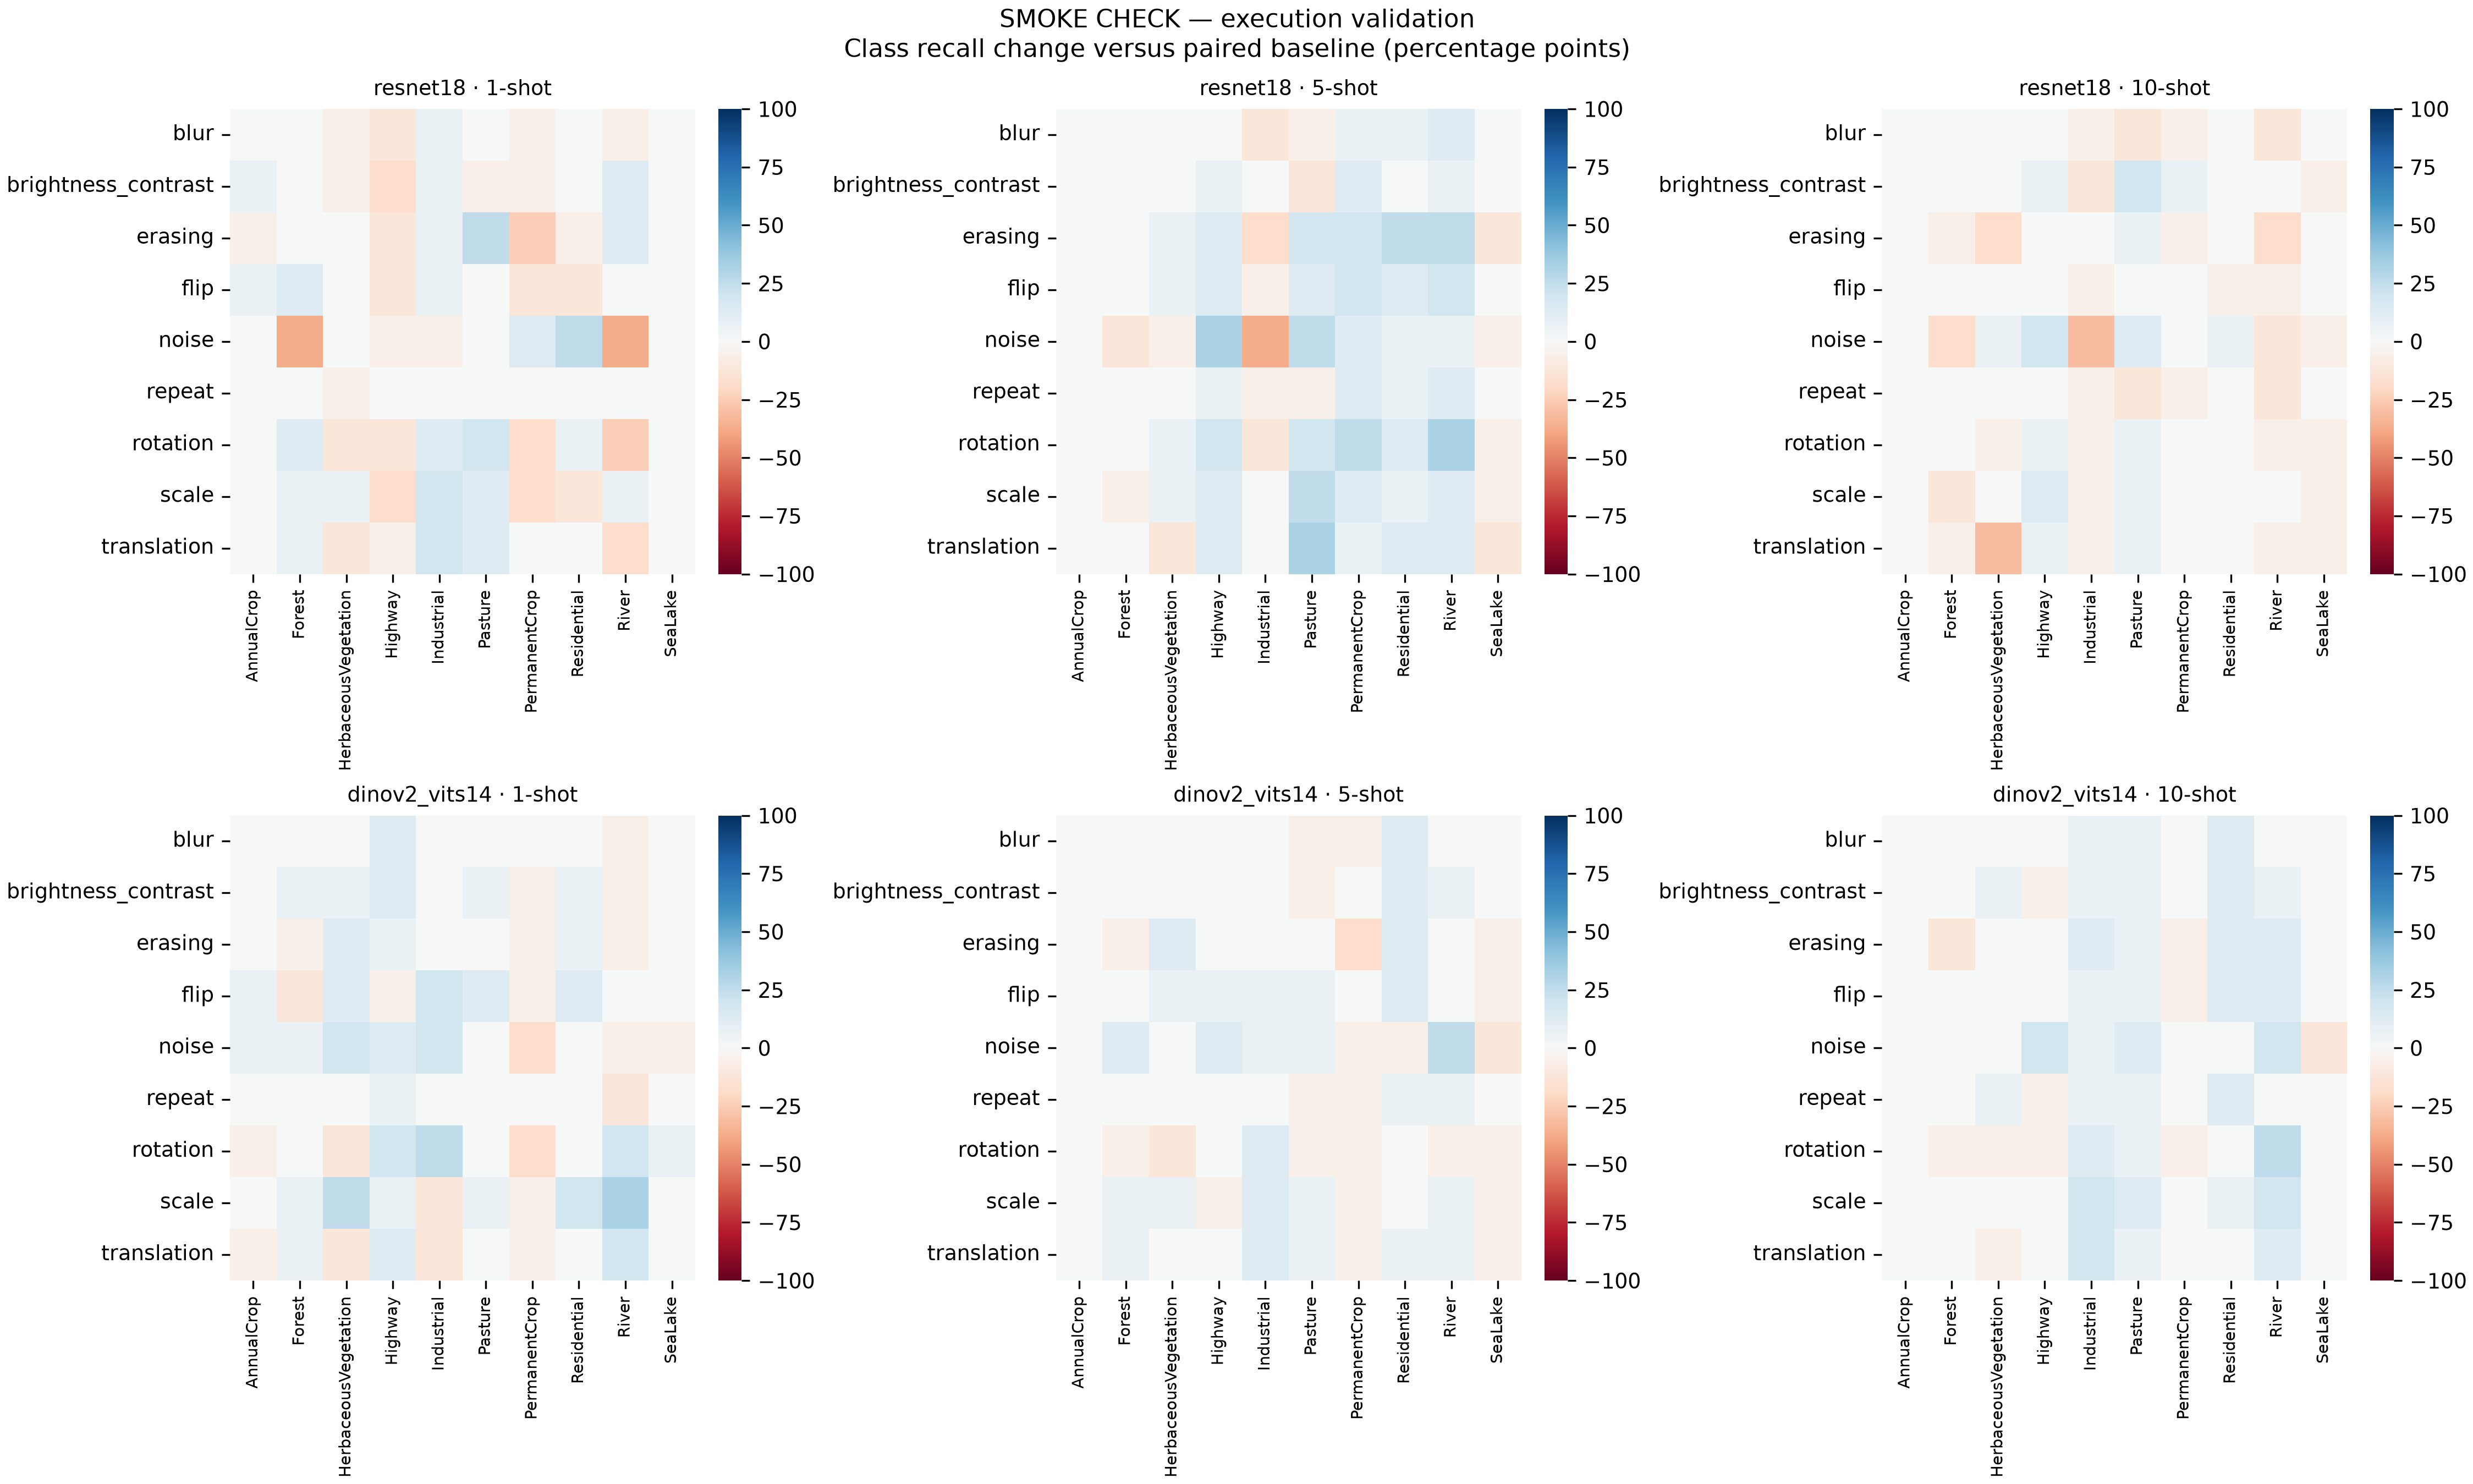

**Classification metrics**

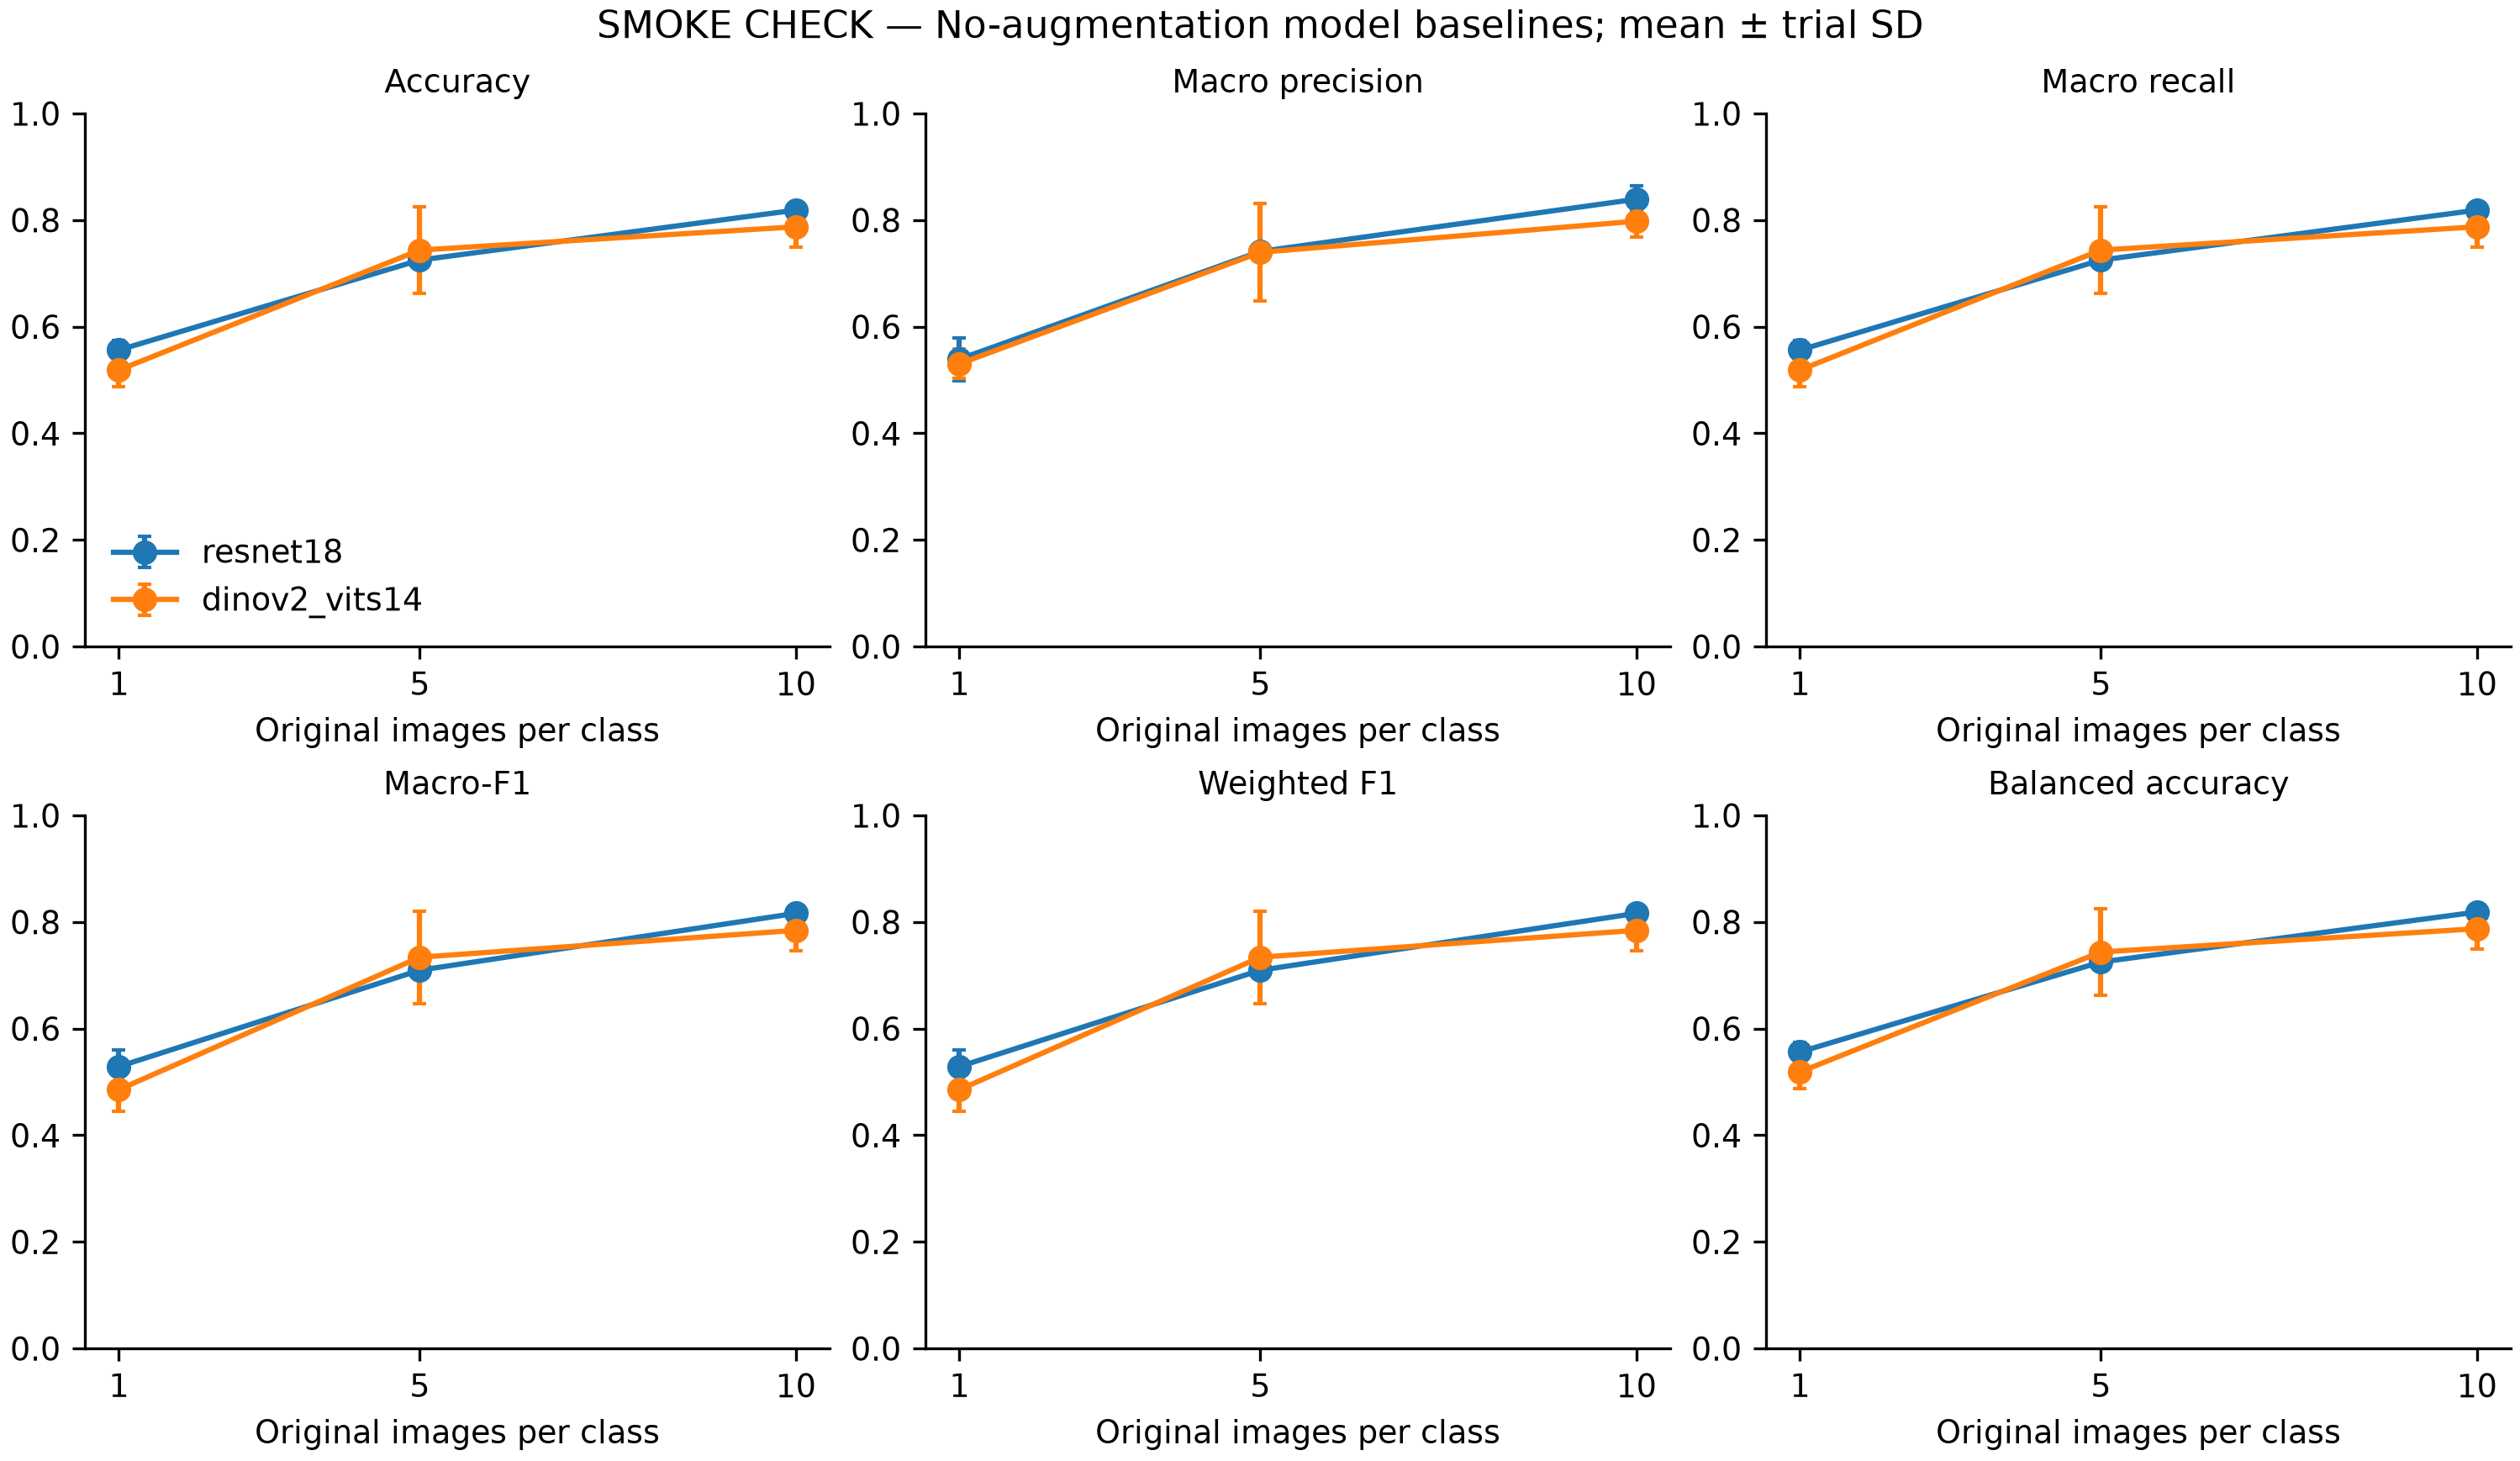

,model,shots,policy,dev_accuracy,accuracy
0,resnet18,1,repeat,0.575,0.550
1,resnet18,5,translation,0.769,0.775
2,resnet18,10,translation,0.825,0.775
3,dinov2_vits14,1,flip,0.575,0.556
4,dinov2_vits14,5,flip,0.769,0.775
5,dinov2_vits14,10,scale,0.837,0.844


PNG/PDF figures, CSV tables and provenance: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/outputs/part-d/401470fd576076ccd1bd7571958978a50b1818ccfb20ec00c8d6ef62281de667/model-baseline/report


**Proposal comparisons: labeled originals and added views**

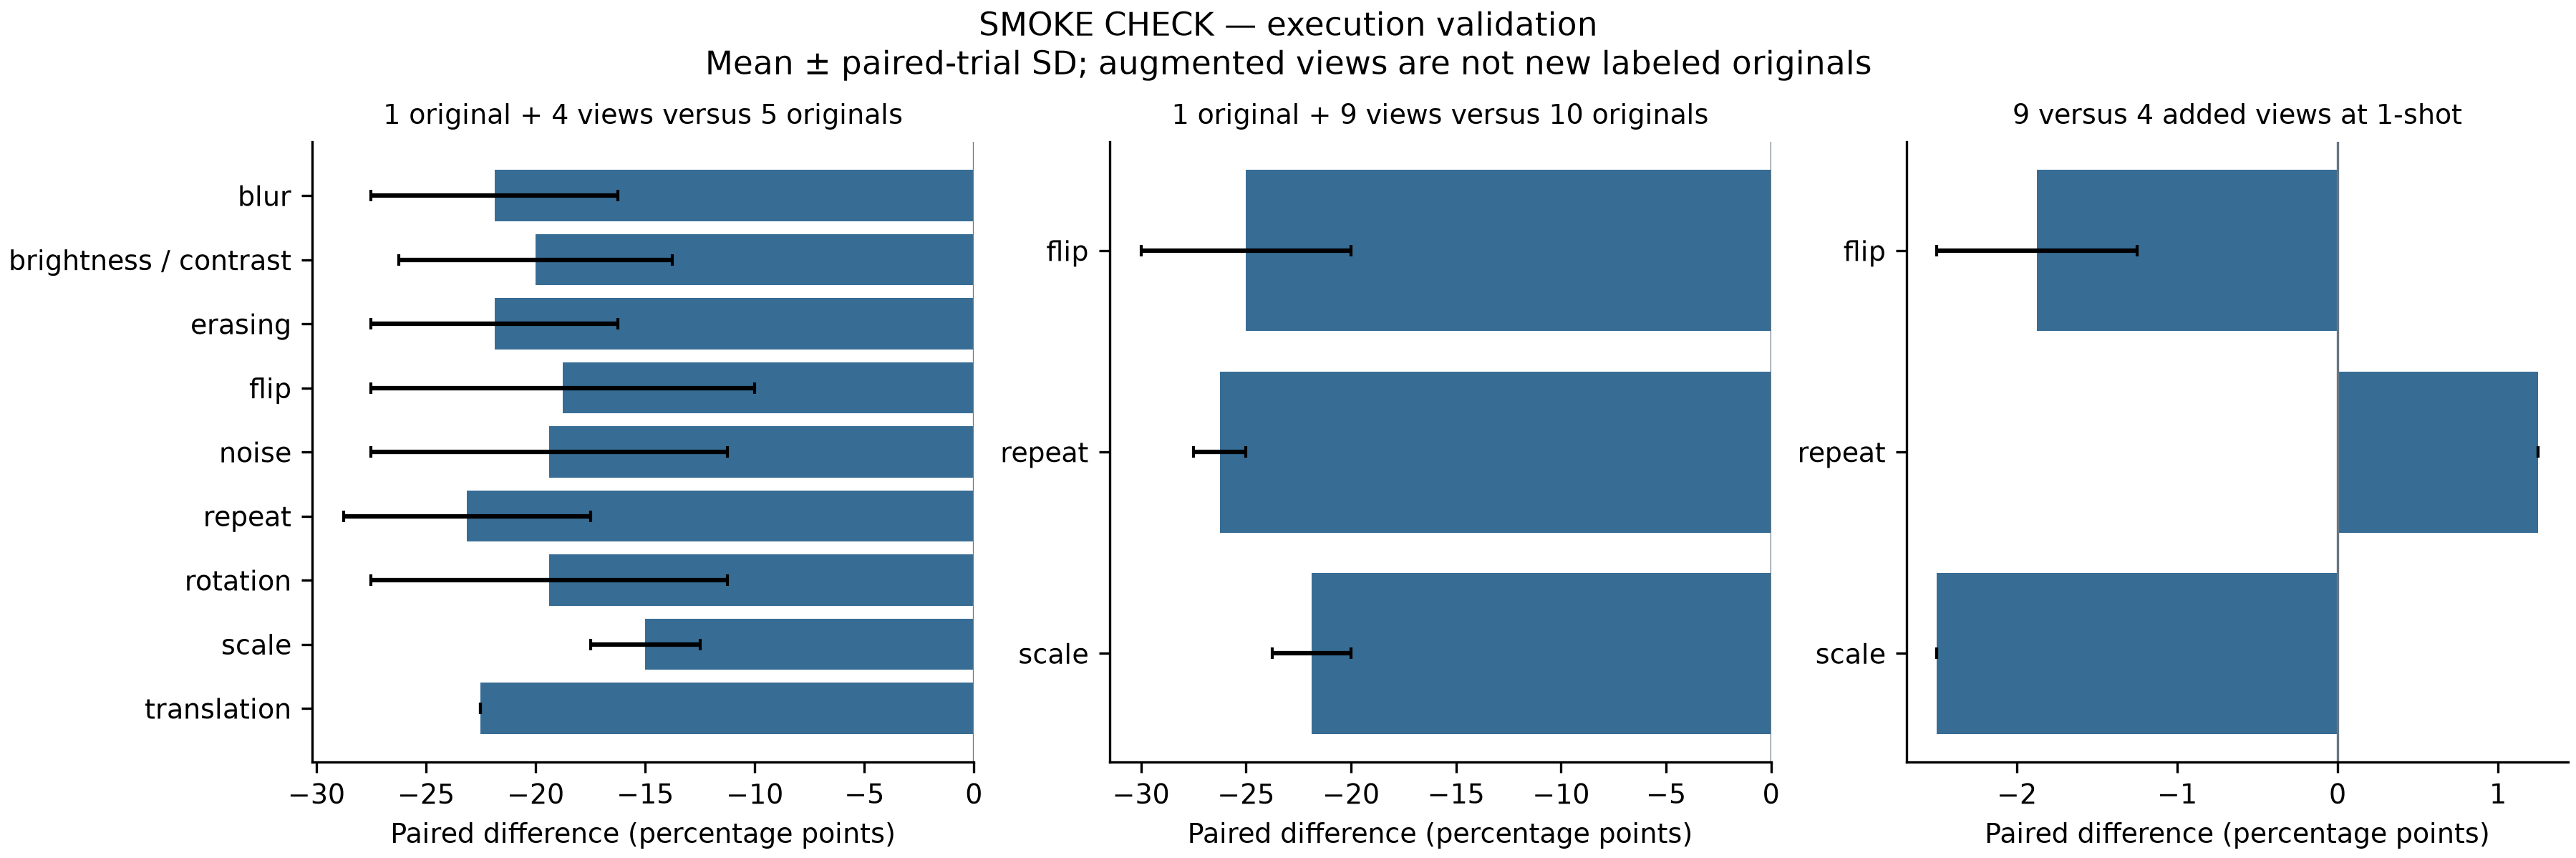

,comparison,model,policy,mean,std,fraction_negative,ci95_low,ci95_high
0,nine_vs_four_views,dinov2_vits14,flip,-1.875,0.625,1.0,NaN,NaN
1,nine_vs_four_views,dinov2_vits14,repeat,1.250,0.000,0.0,NaN,NaN
2,nine_vs_four_views,dinov2_vits14,scale,-2.500,0.000,1.0,NaN,NaN
3,one_plus_four_vs_five_originals,dinov2_vits14,blur,-21.875,5.625,1.0,NaN,NaN
4,one_plus_four_vs_five_originals,dinov2_vits14,brightness_contrast,-20.000,6.250,1.0,NaN,NaN
5,one_plus_four_vs_five_originals,dinov2_vits14,erasing,-21.875,5.625,1.0,NaN,NaN
6,one_plus_four_vs_five_originals,dinov2_vits14,flip,-18.750,8.750,1.0,NaN,NaN
7,one_plus_four_vs_five_originals,dinov2_vits14,noise,-19.375,8.125,1.0,NaN,NaN
8,one_plus_four_vs_five_originals,dinov2_vits14,repeat,-23.125,5.625,1.0,NaN,NaN
9,one_plus_four_vs_five_originals,dinov2_vits14,rotation,-19.375,8.125,1.0,NaN,NaN


Nine-view methods selected on development accuracy: ['flip', 'scale']


,model,policy,shots,class,precision,recall,f1,precision_std,recall_std,f1_std,query_images_per_trial
170,dinov2_vits14,none,10,AnnualCrop,0.778,1.000,0.871,0.111,0.000,0.071,8
171,dinov2_vits14,none,10,Forest,0.938,0.875,0.904,0.062,0.000,0.029,8
172,dinov2_vits14,none,10,HerbaceousVegetation,0.789,0.938,0.856,0.011,0.062,0.033,8
173,dinov2_vits14,none,10,Highway,0.575,0.625,0.597,0.175,0.125,0.153,8
174,dinov2_vits14,none,10,Industrial,0.708,0.750,0.728,0.042,0.000,0.022,8
175,dinov2_vits14,none,10,Pasture,0.845,0.688,0.757,0.012,0.062,0.043,8
176,dinov2_vits14,none,10,PermanentCrop,0.764,0.812,0.787,0.014,0.062,0.037,8
177,dinov2_vits14,none,10,Residential,0.875,0.875,0.875,0.000,0.000,0.000,8
178,dinov2_vits14,none,10,River,0.708,0.438,0.536,0.042,0.062,0.036,8
179,dinov2_vits14,none,10,SeaLake,1.000,0.875,0.933,0.000,0.000,0.000,8


In [23]:
report = (suite['comparison_report'] or suite['primary_report']) if suite is not None else create_report(Path(results['output']) / 'results.json')
for name, filename in report['figures'].items():
    display(Markdown('**' + name.replace('_', ' ').capitalize() + '**'))
    display(NotebookImage(filename=filename, width=900))
display(pd.DataFrame(report['selected'])[['model', 'shots', 'policy', 'dev_accuracy', 'accuracy']].round(3))
print('PNG/PDF figures, CSV tables and provenance:', report['output'])
if suite is not None:
    display(Markdown('**Proposal comparisons: labeled originals and added views**'))
    for filename in suite['comparisons']['figures'].values():
        display(NotebookImage(filename=filename, width=1100))
    display(pd.read_csv(Path(suite['comparisons']['output']) / 'budget-summary.csv').round(3))
    print('Nine-view methods selected on development accuracy:', suite['selected_methods'])
classification = pd.read_csv(Path(report['output']) / 'classification-report.csv')
display(classification[(classification.policy == 'none') & (classification.shots == max(config.shots))].round(3))
